# Attribute QC_CV — кросс-плот и кросс-валидация для оценки качества атрибутного анализа по данным скважин

Оценивается связь между эталонным свойством пласта, измеренным в скважинах (H_eff или Phi), и сейсмическим атрибутом, снятым в тех же точках. Ноутбук показывает шаги 0–5 на данных скважин. Расчёты выполняет движок `attribute_qc_full.py`, тот же, что в приложении `app_full.py`.

Для запуска нужны `attribute_qc_full.py` рядом с ноутбуком и файл данных скважин `data/attribute_wells_100.csv` (путь `RAW`), лежащий в папке `data/`.

Автор: Алексей · геофизик → data scientist


## Описание проекта

Streamlit-инструмент (`app_full.py`) сравнивает эталонный параметр PARAM_1 (H_eff или Phi) и сравниваемый PARAM_2 (сейсмический атрибут) в одних и тех же точках, скважинах, и проверяет, насколько один параметр предсказывается по другому. Реализованы шаги 0–5: загрузка и QC данных, базовый QC-кросс-плот с аппроксимациями, кросс-валидация по девяти схемам с автоматическим выбором лучшей, анализ по категориям, фильтрация скважин и многоатрибутная регрессия отдельно для H_eff и для Phi. В одноатрибутных шагах модель — линейная регрессия (полином степени 1).


## Описание данных

Входная таблица CSV/XLSX: каждая строка — пара значений PARAM_1 и PARAM_2 в точке скважины (на горизонт). Обязательные колонки: `well_id`, `X`, `Y`, эталонный параметр (`H_eff` или `Phi`) и сейсмические атрибуты. Опциональные: `horizon_id`, `tectonic_zone`, `reservoir_flag` (тип коллектора), `fluid_type` (тип флюида) и любые другие числовые и категориальные колонки.

Демонстрационный набор в ноутбуке синтетический, с такой структурой: `well_id, X, Y, H_eff, Phi, rms_amplitude, envelope, sweetness, inst_freq, horizon_id, tectonic_zone, reservoir_flag`. Атрибуты `rms_amplitude` и `envelope` почти дублируют друг друга, а `inst_freq` независим: на этом видно, как работает правило мультиколлинеарности в шаге 5. Для реальных выводов подставьте свой файл в `RAW`.


## Цели исследования

- Проверить, насколько выбранный атрибут (PARAM_2) предсказывает эталонное свойство пласта (PARAM_1) в скважинах.
- Оценить реальную, а не оптимистичную точность связи с помощью кросс-валидации по схемам, которые разбивают данные по скважинам.
- Выявить систематические смещения (Bias, наклон регрессии) и категории (зоны, горизонты, коллекторы, флюиды), где связь работает хуже.
- Проверить устойчивость результата к исключению скважин.
- Подобрать многоатрибутную модель отдельно для H_eff и для Phi (шаг 5) и понять, даёт ли она выигрыш перед лучшей одноатрибутной моделью.


## Постановка задачи

- Оценивается предиктивная модель (линейная регрессия), связывающая сейсмический атрибут с эффективной мощностью коллектора (H_eff) или пористостью (Phi).
- Входные данные — значения атрибутов в точках скважин, извлечённые из сейсмики один раз. При кросс-валидации они не пересчитываются. Переобучается только связь «атрибут → свойство пласта» при исключении скважины или группы скважин.
- Главный риск — ложная (случайная) корреляция. При малом числе скважин и большом числе атрибутов-кандидатов почти всегда найдётся атрибут, который «случайно» коррелирует с целевым параметром (Kalkomey, 1997). Поэтому один высокий R² на всех скважинах недостаточен: нужны кросс-валидация и p-value.
- H_eff и Phi анализируются раздельно. У каждого свойства обычно свой оптимальный атрибут и своя чувствительность.

Инструмент обобщён на любые пары числовых параметров, например атрибут ↔ атрибут для проверки мультиколлинеарности. Пример есть в конце ноутбука.


## Формат данных

Минимальная структура входной таблицы (CSV/XLSX). Имена колонок в файле могут быть любыми. Соответствие задаётся при сопоставлении (в приложении — в сайдбаре, в ноутбуке — переменными в ячейке настроек).

| Колонка в коде | Роль | Описание |
|---|---|---|
| well_id | обязательная | Идентификатор скважины |
| X_coord, Y_coord | обязательные | Координаты скважины (в файле X и Y, при загрузке переименовываются) |
| Zprm_well (= PARAM_1) | обязательная · Reference | Эталонный параметр: H_eff или Phi |
| Zprm_map (= PARAM_2) | обязательная · Compared | Сейсмический атрибут в той же скважине (rms_amplitude, envelope, sweetness и др.) |
| horizon_id | опциональная | Горизонт. Для строгой оценки CV рекомендуется один горизонт |
| tectonic_zone | опциональная | Зона. Используется в схеме Stratified by Zone и в Шаге 3 |
| любая другая колонка | опциональная | Числовая: корреляционный анализ (Шаг 0). Категориальная: анализ по категориям (Шаг 3) |

- Единицы PARAM_1 и PARAM_2 задаются пользователем и используются только в подписях. По умолчанию для H_eff — метры, для Phi — доли.
- При загрузке выполняется очистка: мусорные значения («NA», «NULL», «—», «?») становятся NaN, запятая заменяется на точку, строки с пропусками в обязательных колонках удаляются (с отчётом о числе удалённых строк).


## Метрики кросс-плота и обозначения

Обозначения: x = PARAM_2 (атрибут), y = PARAM_1 (эталонное значение). В кросс-валидации (шаг 2) роли другие: x = Actual (PARAM_1), y = Predicted.

**Невязка Δ зависит от раздела:**

- Базовый QC-кросс-плот (шаг 1, `BasicStats`): Δ = y − x = PARAM_1 − PARAM_2.
- Аппроксимации и кросс-валидация (`FitStats`, `fold_metrics`): Δ = Predicted − Actual, то есть обратный знак.
- Графики CV-невязок в шаге 2 строятся как PARAM_1 − Predicted.

**Важно для атрибутного QC.** H_eff (метры) и атрибут (условные единицы) имеют разные размерности. Поэтому абсолютные невязки (Bias, RMSE, MAE, Std, WAPE) сравнимы только внутри одной пары PARAM_1–PARAM_2 и не переносятся на другой атрибут. Качество связи оценивайте по R² и коэффициентам корреляции, а также по out-of-sample метрикам шага 2.

| Метрика | Формула | Где используется |
|---|---|---|
| Пирсон r | $r = \mathrm{cov}(a,b)/(\sigma_a\sigma_b)$ | Шаг 0, 1, 2, 4 |
| Спирмен ρ | Пирсон на рангах; любая монотонная связь | Шаг 0 |
| R²_lin | $r^2$ (квадрат корреляции, `linregress`) | Шаг 1, базовый QC-кросс-плот |
| R²_fit | $1 - \sum\Delta^2 / \sum(y-\bar y)^2$, Δ = Predicted − Actual (`r2_score`) | Аппроксимации, шаги 1–3 |
| R² (Pearson), out-of-sample | $\mathrm{corr}(\text{Actual}, \text{Predicted})^2$ по out-of-fold прогнозам | Шаг 2 |
| R² (Actual = Predicted) | $1 - \sum\Delta^2/\sum(\text{Actual}-\bar{\text{Actual}})^2$ | Шаг 2, сравнение схем |
| RMSE, MSE, MAE | $\sqrt{\overline{\Delta^2}}$, $\overline{\Delta^2}$, $\overline{\lvert\Delta\rvert}$ | Все шаги |
| Bias | $\overline{\Delta}$ (среднее невязки) | Все шаги |
| WAPE, % | $100\cdot\sum\lvert\Delta\rvert / \sum\lvert y\rvert$ | Все шаги |
| p-value | $t = r\sqrt{(N-2)/(1-r^2)}$, $p = 2(1-F_{t,N-2}(\lvert t\rvert))$; порог значимости обычно 0.05 | Шаги 0, 1, 2, 4 |
| Уравнение регрессии | $y = a + b\cdot x$ (`linregress`) | Шаги 1, 2, 4, 5 |

В проекте два разных R², и их нельзя сравнивать напрямую. R²_lin (шаг 1) — это квадрат корреляции и мера линейной связи. R²_fit (аппроксимации) — доля объяснённой дисперсии для кривой любой формы. Для линейной OLS-модели они совпадают численно, для остальных кривых — нет.

**In-sample и out-of-sample.** In-sample: модель подбирается и проверяется на одних и тех же скважинах, поэтому метрики оптимистичны. Out-of-sample: модель подбирается без части скважин и проверяется на исключённых. Разрыв между ними — признак переобучения.


## Типы линий аппроксимации

На кросс-плоте доступны 17 типов аппроксимации: 10 полиномов (степени 1–10) и 7 прочих методов. Отдельно выводится квантильная регрессия (τ = 0.1 / 0.5 / 0.9).

| Метод | Вид уравнения | Примечание |
|---|---|---|
| Linear, Quadratic, Cubic, Polynomial 4–10 | $y = \sum_k a_k x^k$ | степень 1–10 |
| Power Law | $y = a x^b$ | только $x, y > 0$ |
| Exponential | $y = a e^{bx}$ | только $y > 0$ |
| Logarithmic | $y = a + b\ln x$ | только $x > 0$ |
| Robust (Huber) | $y = a + bx$, устойчивая оценка | коэффициенты другие, форма та же |
| Theil–Sen | $y = a + bx$, $b$ — медиана попарных наклонов | устойчив к выбросам |
| RANSAC | $y = a + bx$, по максимуму inlier-точек | устойчив к выбросам |
| LOWESS | локальная регрессия, frac = 0.3 | даёт кривую, а не формулу |
| Quantile (τ = 0.1 / 0.5 / 0.9) | $y = a_\tau + b_\tau x$, минимизация $\sum \rho_\tau$ | для τ = 0.1 и 0.9 R² может быть отрицательным |

Для Huber, Theil–Sen и RANSAC уравнение остаётся линейным, но коэффициенты оцениваются иначе, чем методом наименьших квадратов.


## Типы кросс-валидации (от худшей оценки к лучшей)

| Метод | Суть | Когда применять |
|---|---|---|
| Random K-Fold | случайные k фолдов по скважинам | Не использовать как основной метод: даёт завышенную точность, так как игнорирует пространственную корреляцию. Оставлен как оптимистичная база для контраста |
| Random K-Fold (buffered) | тот же случайный KFold, но из обучения удаляются скважины ближе `buffer` к тестовой | Показывает, насколько обычный Random K-Fold был завышен соседними скважинами |
| Leave-One-Well-Out (LOWO) | исключается вся скважина целиком | Стандарт при малом числе скважин (меньше 20–30) |
| Block CV | площадь делится сеткой `grid_n × grid_n`, тест — один блок | Для равномерной сетки скважин |
| Buffered CV | как Block CV, но с буфером вокруг границы блока | Снижает остаточную пространственную корреляцию |
| Leave-P-Out | случайно выбирается `p%` скважин, повторяется `repeats` раз, прогноз усредняется | Проверка устойчивости к составу тестовой выборки |
| Spatial Leave-P-Out | тест — все скважины в радиусе от случайного центра | Ближе всего к сценарию прогноза новой области |
| Stratified by {колонка} | тест — вся зона (категория) целиком | Лучший вариант для проверки переносимости на новую зону |
| Distance-based exclusion CV | для каждой скважины из обучения убираются скважины ближе радиуса корреляции | Практическая эвристика на расстояниях, а не полноценная вариограмма |

Автоматические параметры рекомендуются по числу скважин `n` и медианному расстоянию между ними. Все значения можно поменять вручную (в приложении — слайдерами в сайдбаре).

**Выбор лучшей схемы:** `score = RMSE + RMSE_fold_std → min`. Random K-Fold участвует в выборе. Это известное ограничение, см. раздел «Известные ограничения» в конце.


## Шаг 5: многоатрибутная регрессия (H_eff и Phi отдельно)

Шаг 1 строит одноатрибутную модель: `PARAM_1 ~ PARAM_2`. Шаг 5 расширяет её до нескольких атрибутов: `PARAM_1 ~ a + b₁·A₁ + b₂·A₂ + …`. Модели строятся **отдельно для H_eff и отдельно для Phi**.

Логика движка `step5_run`:

- **k_max** = min(3, число кандидатов, max(1, floor(N / 5))). Перебираются все комбинации атрибутов размером от 1 до k_max.
- **Мультиколлинеарность:** пары атрибутов с |r| > 0.8 не входят в одну модель.
- **Ограничения:** для H_eff значения не ограничиваются сверху, для Phi — не выше 1.0.
- **Оценка:** LOWO и K-fold с K = max(3, round(N/10)). Критерий ранжирования — RMSE_cv.
- **In-sample** (вся выборка, OLS) и **out-of-sample** (CV) метрики считаются отдельно. Уравнение CV — среднее коэффициентов по фолдам.

Вопрос, на который отвечает шаг: даёт ли многоатрибутная модель заметный выигрыш по RMSE_cv относительно лучшей одноатрибутной? Если выигрыш мал, дополнительные атрибуты не оправданы: они добавляют риск ложной корреляции.


## Практическая схема пайплайна

- Сбор данных: `well_id`, `X_coord`, `Y_coord`, PARAM_1, PARAM_2, `horizon_id`, `tectonic_zone` (опционально), кандидаты-атрибуты.
- Базовый анализ (шаги 0–1): корреляции, распределения, базовый кросс-плот и аппроксимации.
- Кросс-валидация по скважинам (шаг 2): LOWO, Block, Buffered, Spatial Leave-P-Out, Distance-based exclusion, Stratified by Zone.
- Диагностика по категориям (шаг 3) и фильтрация выборки (шаг 4, серия 4.5).
- Многоатрибутная модель отдельно для H_eff и Phi (шаг 5).
- Интерпретация: сравнить out-of-sample метрики разных схем и моделей, выделить зоны и категории систематических ошибок, решить, нужна ли многоатрибутная модель.


<a class="anchor" id="contents"></a>
# Содержание:<a class="anchor" id="ch8"></a>

* [Загрузка данных](#ch8_1)
* [Шаг 1: Базовый QC-кросс-плот](#ch8_2)
* [Шаг 2: Кросс-валидация](#ch8_3)
* [Шаг 3: Диагностика по категориям](#ch8_4)
* [Шаг 4: Фильтрация скважин](#ch8_5)
* [Шаг 5: Многоатрибутная регрессия](#ch8_7)
* [Выводы](#ch8_6)


# Ход исследования

# Выполнение проекта

## __Загрузка данных__ <a class="anchor" id="ch8_1"></a>


Ожидаемый формат файла: `well_id, X, Y, H_eff, Phi` и сейсмические атрибуты (`rms_amplitude, envelope, sweetness`, при наличии также `inst_freq`); опционально `horizon_id, tectonic_zone, reservoir_flag`. Атрибуты, которых нет в файле, пропускаются автоматически, и ноутбук печатает список использованных.

Движок работает с именами `well_id, X_coord, Y_coord, Zprm_well, Zprm_map`. Поэтому при загрузке `X, Y` переименовываются в `X_coord, Y_coord`, а PARAM_1 и PARAM_2 копируются в `Zprm_well` и `Zprm_map`. Остальные колонки (H_eff, Phi и атрибуты-кандидаты) сохраняются для шага 5.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path
from scipy.stats import gaussian_kde
from scipy.spatial.distance import pdist

import attribute_qc_full as sq

mpl.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#333333",
    "axes.grid": True,
    "grid.color": "#E5E5E5",
    "font.size": 11,
})
RED, BLUE = "#C23A22", "#2F5FA8"
plt.rcParams["figure.max_open_warning"] = 0   # много графиков в ячейках: не выводить предупреждение


In [2]:
# ---------- Настройки пары параметров ----------
RAW = Path("data/attribute_wells_100.csv")   # файл с данными скважин (CSV)
PARAM_1 = "H_eff"            # эталонный параметр: H_eff или Phi
PARAM_2 = "rms_amplitude"    # сравниваемый параметр (шаг 1–4): сейсмический атрибут
PARAM_1_UNIT = "м"           # H_eff — метры, Phi — доли (подписи графиков)
PARAM_2_UNIT = "ед."
ATTRIBUTES_CANDIDATES = ["rms_amplitude", "envelope", "sweetness", "inst_freq"]   # кандидаты-атрибуты; берутся те, что есть в файле
REQUIRED = ["well_id", "X_coord", "Y_coord", "Zprm_well", "Zprm_map"]


In [3]:
raw = pd.read_csv(RAW, na_values=["NA", "NULL", "—", "?", ""], dtype=str)
raw.columns = raw.columns.str.strip()
df = raw.rename(columns={"X": "X_coord", "Y": "Y_coord"}).copy()

NUMERIC_IN = ["X_coord", "Y_coord", "H_eff", "Phi"] + ATTRIBUTES_CANDIDATES
for c in [c for c in NUMERIC_IN if c in df.columns]:
    df[c] = pd.to_numeric(df[c].str.replace(",", ".", regex=False), errors="coerce")

# Движок работает с Zprm_well (PARAM_1) и Zprm_map (PARAM_2); остальные колонки сохраняются для шага 5
df["Zprm_well"] = df[PARAM_1]
df["Zprm_map"] = df[PARAM_2]

n_before = len(df)
df = df.dropna(subset=REQUIRED).reset_index(drop=True)
print(f"n = {len(df)} строк, удалено при очистке: {n_before - len(df)}")

ATTRIBUTES = [a for a in ATTRIBUTES_CANDIDATES if a in df.columns and df[a].notna().any()]
print("Атрибуты для анализа:", ATTRIBUTES)
print(f"Скважин: {df['well_id'].nunique()}, PARAM_1 = {PARAM_1} ({PARAM_1_UNIT}), PARAM_2 = {PARAM_2} ({PARAM_2_UNIT})")
df.head()


n = 200 строк, удалено при очистке: 0
Атрибуты для анализа: ['rms_amplitude', 'envelope', 'sweetness']
Скважин: 100, PARAM_1 = H_eff (м), PARAM_2 = rms_amplitude (ед.)


,well_id,X_coord,Y_coord,horizon_id,tectonic_zone,well_category,reservoir_flag,fluid_type,H_eff,Phi,...,sweetness,coherence,inst_frequency,avo_intercept,avo_gradient,spectral_decomp_20Hz,acoustic_impedance,q_factor,Zprm_well,Zprm_map
0,W-001,7501.1,9671.5,Top_Reservoir,Central_Graben,production,reservoir,oil,5.47,0.223,...,0.1640,0.443,44.19,-0.0968,-0.1178,0.3292,8.081,54.5,5.47,0.1047
1,W-002,10766.6,6577.6,Top_Reservoir,South_Block,appraisal,reservoir,oil,4.19,0.193,...,0.1480,0.671,38.86,-0.0905,-0.0222,0.4752,8.191,75.8,4.19,0.0734
2,W-003,9308.2,4282.2,Top_Reservoir,South_Block,appraisal,reservoir,oil,9.38,0.160,...,0.1983,0.38,13.45,-0.036,-0.1041,0.756,9.659,54.9,9.38,0.0594
3,W-004,2702.5,5237.4,Top_Seal,North_Block,exploration,non_reservoir,non_reservoir,0.00,0.062,...,0.1625,0.96,21.38,0.263,0.2653,0.4128,10.941,46.7,0.00,0.0460
4,W-005,3602.0,8728.1,Top_Reservoir,North_Block,production,reservoir,oil,9.27,0.225,...,0.1990,0.777,29.41,-0.13,-0.0886,0.6171,9.032,57.4,9.27,0.0830


__QC входных данных и статистика (Шаг 0)__

### QC входных данных

- Полные дубликаты строк.
- Дубликаты `well_id`. Для нескольких горизонтов на одну скважину это ожидаемо. Реальное дублирование — только при совпадении `well_id` и `horizon_id`.
- Совпадающие координаты скважин в пределах одного горизонта.
- Пропуски по колонкам.
- Строки, удалённые при очистке.

### Типы данных и категории

- Для каждой колонки: тип (Numeric / Date & Time / Boolean / String), dtype, число непустых и пустых значений, число уникальных значений.
- Список уникальных значений для каждой категориальной колонки.


In [4]:
print("Полных дублей строк:", df.duplicated().sum())
key = ["well_id"] + (["horizon_id"] if "horizon_id" in df.columns else [])
print("Строк с повторяющимся well_id:", df["well_id"].duplicated(keep=False).sum())
print("Реальных дублей (" + " + ".join(key) + "):", df.duplicated(subset=key).sum())
print("Уникальных скважин:", df["well_id"].nunique())
print("\nПропуски по колонкам:")
print(df.isna().sum()[lambda s: s > 0].to_string() or "нет")


Полных дублей строк: 0
Строк с повторяющимся well_id: 200
Реальных дублей (well_id + horizon_id): 0
Уникальных скважин: 100

Пропуски по колонкам:
Series([], )


In [5]:
if "tectonic_zone" in df.columns:
    display(df.groupby("tectonic_zone")[["Zprm_well", "Zprm_map"]].agg(["count", "mean", "std"]).round(2))


Zprm_well             Zprm_map            
                   count  mean   std    count  mean   std
tectonic_zone                                            
Central_Graben        76  5.73  6.87       76  0.09  0.04
North_Block           72  4.22  5.81       72  0.08  0.04
South_Block           52  4.02  5.59       52  0.08  0.04

In [6]:
rows = []
for c in df.columns:
    s = df[c]
    if pd.api.types.is_bool_dtype(s):
        t = "Boolean"
    elif pd.api.types.is_numeric_dtype(s):
        t = "Numeric"
    elif pd.api.types.is_datetime64_any_dtype(s):
        t = "Date & Time"
    else:
        t = "String"
    rows.append({"колонка": c, "тип": t, "dtype": str(s.dtype), "непустых": int(s.notna().sum()),
                 "пустых": int(s.isna().sum()), "уникальных": int(s.nunique())})
display(pd.DataFrame(rows))

for c in df.select_dtypes(exclude="number").columns:
    vals = df[c].dropna().unique()
    print(f"{c} — {len(vals)} значений: {list(vals[:20])}")


,колонка,тип,dtype,непустых,пустых,уникальных
0,well_id,String,object,200,0,100
1,X_coord,Numeric,float64,200,0,100
2,Y_coord,Numeric,float64,200,0,100
3,horizon_id,String,object,200,0,2
4,tectonic_zone,String,object,200,0,3
5,well_category,String,object,200,0,3
6,reservoir_flag,String,object,200,0,2
7,fluid_type,String,object,200,0,4
8,H_eff,Numeric,float64,200,0,102
9,Phi,Numeric,float64,200,0,109


well_id — 100 значений: ['W-001', 'W-002', 'W-003', 'W-004', 'W-005', 'W-006', 'W-007', 'W-008', 'W-009', 'W-010', 'W-011', 'W-012', 'W-013', 'W-014', 'W-015', 'W-016', 'W-017', 'W-018', 'W-019', 'W-020']
horizon_id — 2 значений: ['Top_Reservoir', 'Top_Seal']
tectonic_zone — 3 значений: ['Central_Graben', 'South_Block', 'North_Block']
well_category — 3 значений: ['production', 'appraisal', 'exploration']
reservoir_flag — 2 значений: ['reservoir', 'non_reservoir']
fluid_type — 4 значений: ['oil', 'non_reservoir', 'gas', 'water']
coherence — 171 значений: ['0.443', '0.671', '0.38', '0.96', '0.777', '0.722', '0.755', '0.832', '0.841', '0.396', '0.551', '0.361', '0.866', '0.267', '0.864', '0.954', '0.305', '0.514', '0.924', '0.947']
inst_frequency — 192 значений: ['44.19', '38.86', '13.45', '21.38', '29.41', '18.88', '42.98', '42.85', '22.17', '67.75', '40.56', '44.17', '35.43', '24.94', '48.2', '27.52', '48.84', '26.85', '42.3', '43.48']
avo_intercept — 195 значений: ['-0.0968', '-0.0905'

### Статистика параметров PARAM_1 и PARAM_2

Полный набор статистик: Count, μ, median, mode, σ, variance, CV %, min, Q05, Q25, Q75, Q95, max, range, IQR и границы IQR.


In [7]:
def param_stats(s):
    s = pd.Series(s).dropna().astype(float)
    mu, sd = s.mean(), s.std(ddof=1)
    q05, q25, q50, q75, q95 = s.quantile([0.05, 0.25, 0.5, 0.75, 0.95])
    iqr = q75 - q25
    mode = s.round(2).mode()
    return {
        "Count": len(s), "μ (mean)": mu, "median": q50,
        "mode": mode.iloc[0] if len(mode) else np.nan,
        "σ (std)": sd, "variance": sd ** 2, "CV, %": sd / mu * 100,
        "min": s.min(), "Q05": q05, "Q25": q25, "Q75": q75, "Q95": q95, "max": s.max(),
        "range": s.max() - s.min(), "IQR": iqr,
        "IQR lower bound": q25 - 1.5 * iqr, "IQR upper bound": q75 + 1.5 * iqr,
    }

display(pd.DataFrame({f"{PARAM_1} (PARAM_1)": param_stats(df["Zprm_well"]),
                      f"{PARAM_2} (PARAM_2)": param_stats(df["Zprm_map"])}).round(3))


,H_eff (PARAM_1),rms_amplitude (PARAM_2)
Count,200.000,200.000
μ (mean),4.740,0.087
median,1.110,0.080
mode,0.000,0.060
σ (std),6.201,0.038
variance,38.456,0.001
"CV, %",130.834,43.958
min,0.000,0.024
Q05,0.000,0.044
Q25,0.000,0.061


### Корреляционный анализ

Сначала — корреляция атрибутов между собой (проверка мультиколлинеарности). Затем — корреляция PARAM_1 с атрибутами. Для каждой группы считаются матрица Пирсона (только линейная связь) и матрица Спирмена (любая монотонная связь). Pairplot рекомендуется для не более чем 10 параметров.


In [8]:
cols_p1 = [PARAM_1] + ATTRIBUTES

print("Атрибуты между собой (проверка мультиколлинеарности), Пирсон:")
display(df[ATTRIBUTES].corr(method="pearson").round(2))
print("Атрибуты между собой, Спирмен:")
display(df[ATTRIBUTES].corr(method="spearman").round(2))

print(f"\n{PARAM_1} и атрибуты, Пирсон:")
display(df[cols_p1].corr(method="pearson").round(2))
print(f"{PARAM_1} и атрибуты, Спирмен:")
display(df[cols_p1].corr(method="spearman").round(2))


Атрибуты между собой (проверка мультиколлинеарности), Пирсон:


,rms_amplitude,envelope,sweetness
rms_amplitude,1.00,0.69,0.41
envelope,0.69,1.00,0.60
sweetness,0.41,0.60,1.00


Атрибуты между собой, Спирмен:


,rms_amplitude,envelope,sweetness
rms_amplitude,1.00,0.72,0.42
envelope,0.72,1.00,0.58
sweetness,0.42,0.58,1.00



H_eff и атрибуты, Пирсон:


,H_eff,rms_amplitude,envelope,sweetness
H_eff,1.00,0.71,0.47,0.63
rms_amplitude,0.71,1.00,0.69,0.41
envelope,0.47,0.69,1.00,0.60
sweetness,0.63,0.41,0.60,1.00


H_eff и атрибуты, Спирмен:


,H_eff,rms_amplitude,envelope,sweetness
H_eff,1.00,0.66,0.41,0.57
rms_amplitude,0.66,1.00,0.72,0.42
envelope,0.41,0.72,1.00,0.58
sweetness,0.57,0.42,0.58,1.00


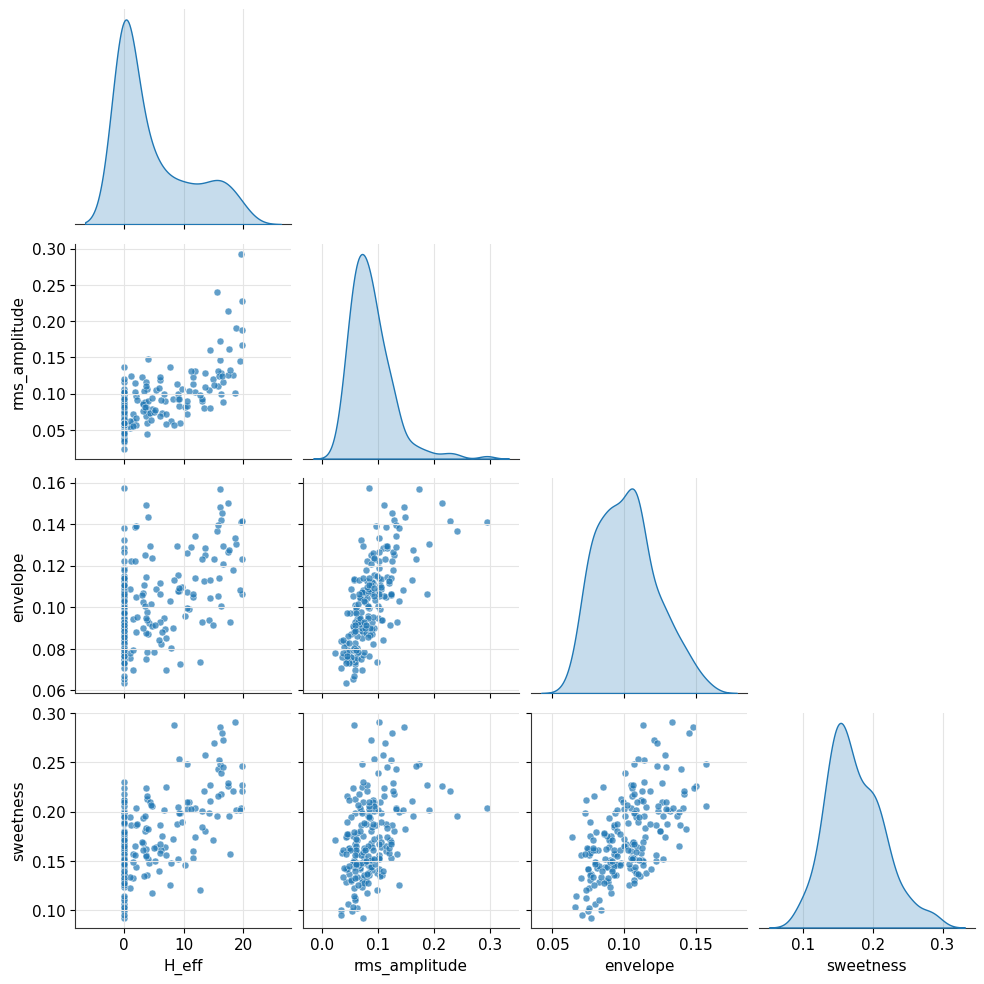

In [9]:
try:
    import seaborn as sns
    g = sns.pairplot(df[cols_p1], diag_kind="kde", corner=True, plot_kws={"s": 25, "alpha": .7})
    plt.show()
except ImportError:
    print("seaborn не установлен: pairplot пропущен (в приложении доступны Seaborn и Plotly)")


### Распределения числовых колонок

Гистограмма с KDE, средним, медианой и ±3σ, а также boxplot для каждой числовой колонки, кроме well_id и PARAM_1 / PARAM_2 (их распределения выводятся в Шаге 1).


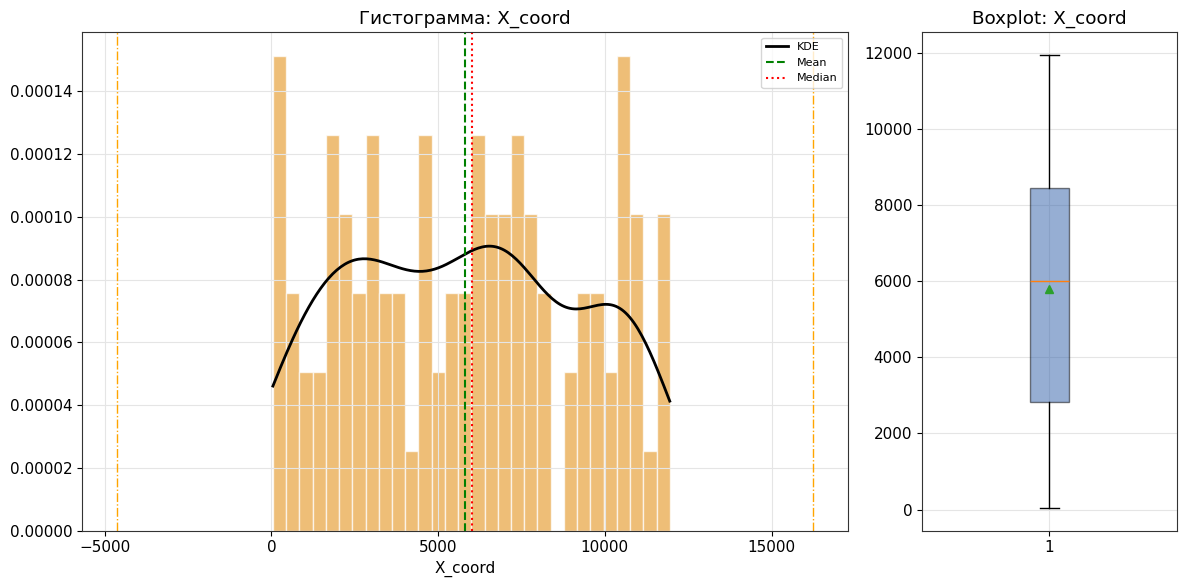

,X_coord
Count,2.000000e+02
μ (mean),5.806579e+03
median,6.008550e+03
mode,4.480000e+01
σ (std),3.476714e+03
variance,1.208754e+07
"CV, %",5.987500e+01
min,4.480000e+01
Q05,4.250000e+02
Q25,2.831050e+03


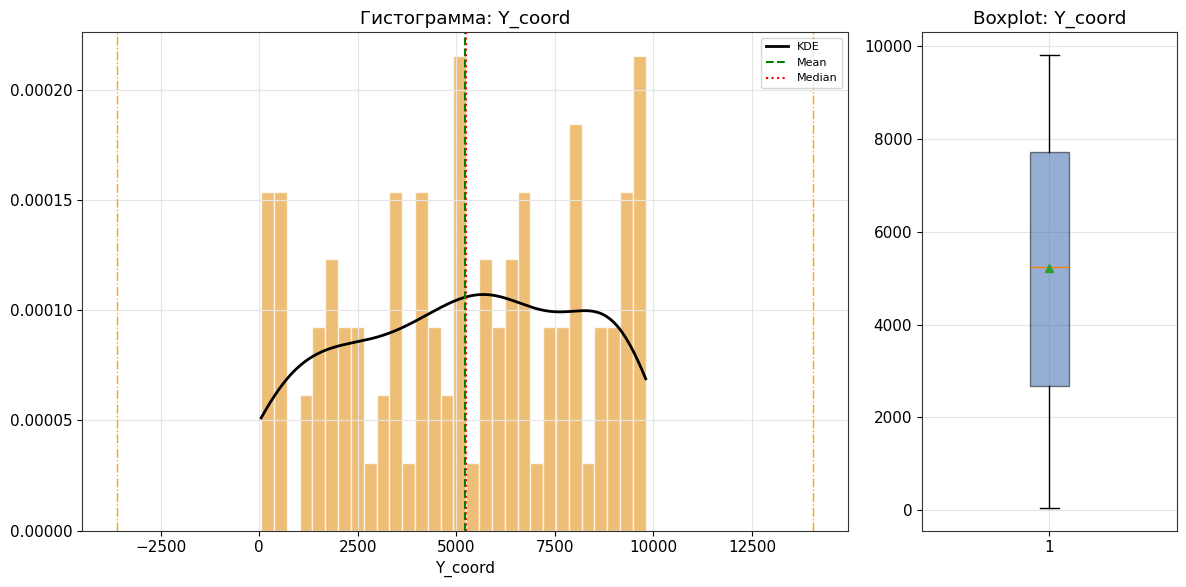

,Y_coord
Count,200.000
μ (mean),5220.192
median,5235.200
mode,51.800
σ (std),2940.272
variance,8645198.263
"CV, %",56.325
min,51.800
Q05,385.550
Q25,2668.325


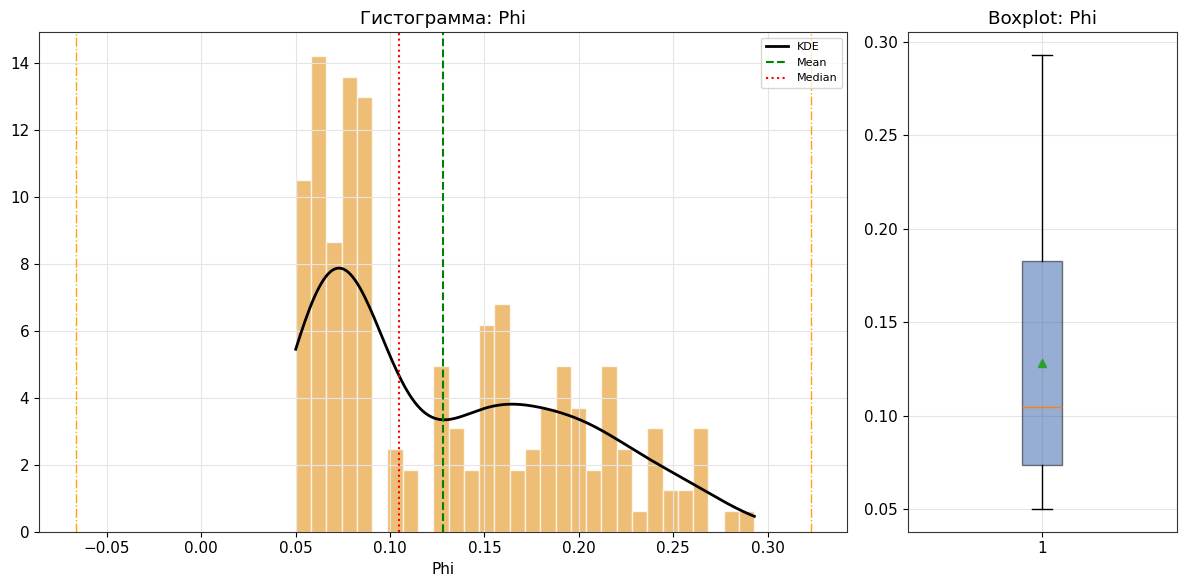

,Phi
Count,200.000
μ (mean),0.128
median,0.104
mode,0.080
σ (std),0.065
variance,0.004
"CV, %",50.651
min,0.050
Q05,0.057
Q25,0.074


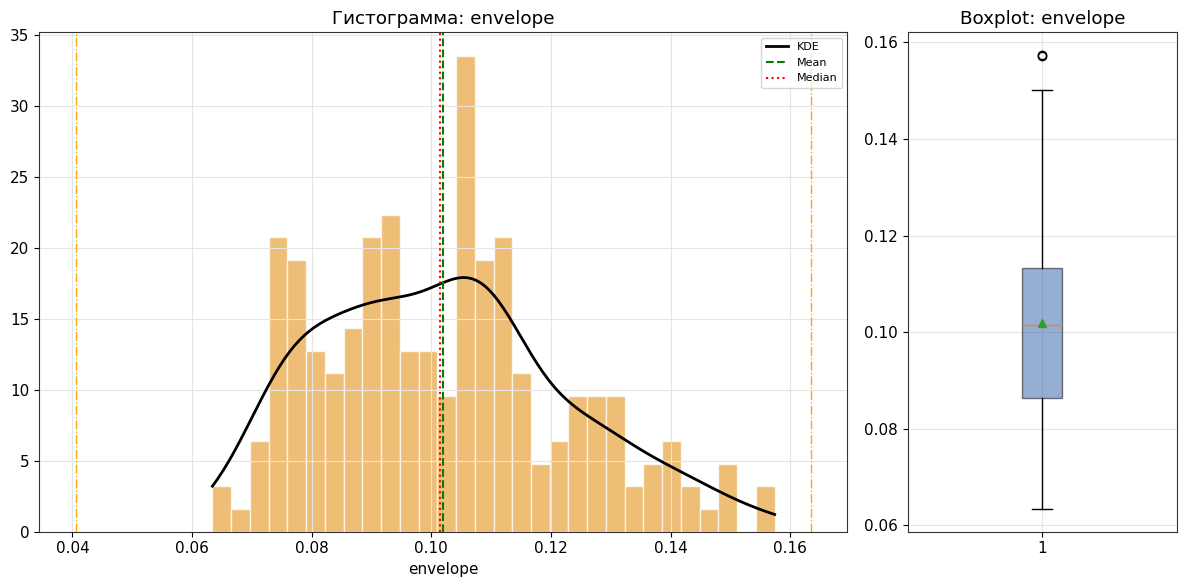

,envelope
Count,200.000
μ (mean),0.102
median,0.101
mode,0.110
σ (std),0.020
variance,0.000
"CV, %",20.075
min,0.063
Q05,0.074
Q25,0.086


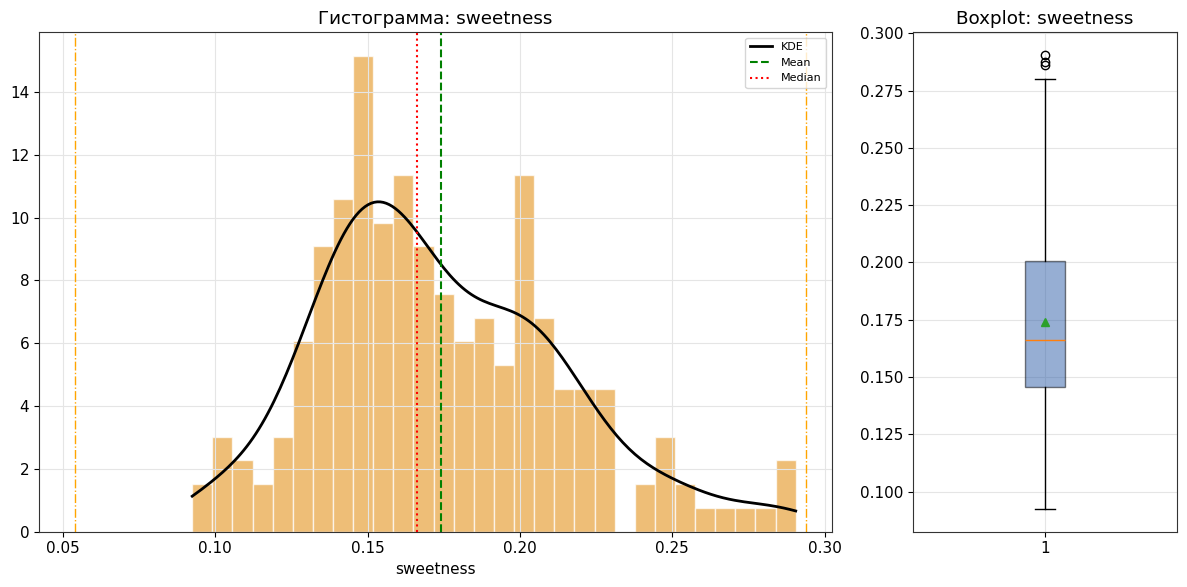

,sweetness
Count,200.000
μ (mean),0.174
median,0.166
mode,0.150
σ (std),0.040
variance,0.002
"CV, %",22.996
min,0.092
Q05,0.117
Q25,0.146


In [46]:
from scipy.stats import gaussian_kde

# Все числовые колонки, кроме well_id и самих PARAM_1 / PARAM_2 (их распределения — в шаге 1)
num_cols = [c for c in df.select_dtypes(include="number").columns
            if c not in ("well_id", "Zprm_well", "Zprm_map", PARAM_1, PARAM_2)]

for col in num_cols:
    vals = df[col].to_numpy(float)
    vals = vals[np.isfinite(vals)]

    fig, (ax_h, ax_b) = plt.subplots(1, 2, figsize=(12, 6),
                                     gridspec_kw={"width_ratios": [3, 1]})
    ax_h.hist(vals, bins=30, density=True, color="#E8A33D", alpha=.7, edgecolor="white")
    if len(np.unique(vals)) > 1:
        xs = np.linspace(vals.min(), vals.max(), 200)
        ax_h.plot(xs, gaussian_kde(vals)(xs), color="black", lw=2, label="KDE")
    m, md, sd = vals.mean(), np.median(vals), vals.std(ddof=1)
    ax_h.axvline(m, color="green", ls="--", label="Mean")
    ax_h.axvline(md, color="red", ls=":", label="Median")
    for k in (-3, 3):
        ax_h.axvline(m + k * sd, color="orange", ls="-.", lw=1)
    ax_h.set_title(f"Гистограмма: {col}")
    ax_h.set_xlabel(col)
    ax_h.legend(fontsize=8)

    ax_b.boxplot(vals, showmeans=True, patch_artist=True, boxprops=dict(facecolor=BLUE, alpha=.5))
    ax_b.set_title(f"Boxplot: {col}")

    plt.tight_layout(); plt.show()
    display(pd.DataFrame({col: param_stats(vals)}).round(3))


<div class="alert alert-info">
  <b> * <a href="#ch8">к содержанию</a> </b>
</div>

---

## Шаг 1: __Базовый QC-кросс-плот__ <a class="anchor" id="ch8_2"></a>

Базовый кросс-плот PARAM_1 (эталон) против PARAM_2 (атрибут), линейная регрессия (OLS) и метрики кросс-плота: R²_lin, наклон, p-value, RMSE, MAE, Bias, Std, WAPE. Основная оценка связи — R², наклон и p-value. Анализ невязок и выбросов в этом шаге не проводится: он относится к шагу 2, где невязки центрированы на предсказаниях кросс-валидации.


In [11]:
basic = sq.basic_crossplot_stats(df)
print(f"R²_lin  = {basic.r2:.3f}   (r = {basic.r:+.3f})")
print(f"slope   = {basic.slope:.3f}   intercept = {basic.intercept:+.3f} {PARAM_1_UNIT}")
print(f"p-value = {basic.p_value:.2e}")
print(f"RMSE    = {basic.rmse:.3f} {PARAM_1_UNIT}")
print(f"MAE     = {basic.mae:.3f} {PARAM_1_UNIT}")
print(f"Bias    = {basic.bias:+.3f} {PARAM_1_UNIT}")
print(f"Std     = {basic.std:.3f} {PARAM_1_UNIT}")
print(f"WAPE    = {basic.wape_pct:.2f} %")


R²_lin  = 0.500   (r = +0.707)
slope   = 114.907   intercept = -5.234 м
p-value = 1.29e-31
RMSE    = 7.719 м
MAE     = 4.718 м
Bias    = +4.653 м
Std     = 6.174 м
WAPE    = 99.54 %


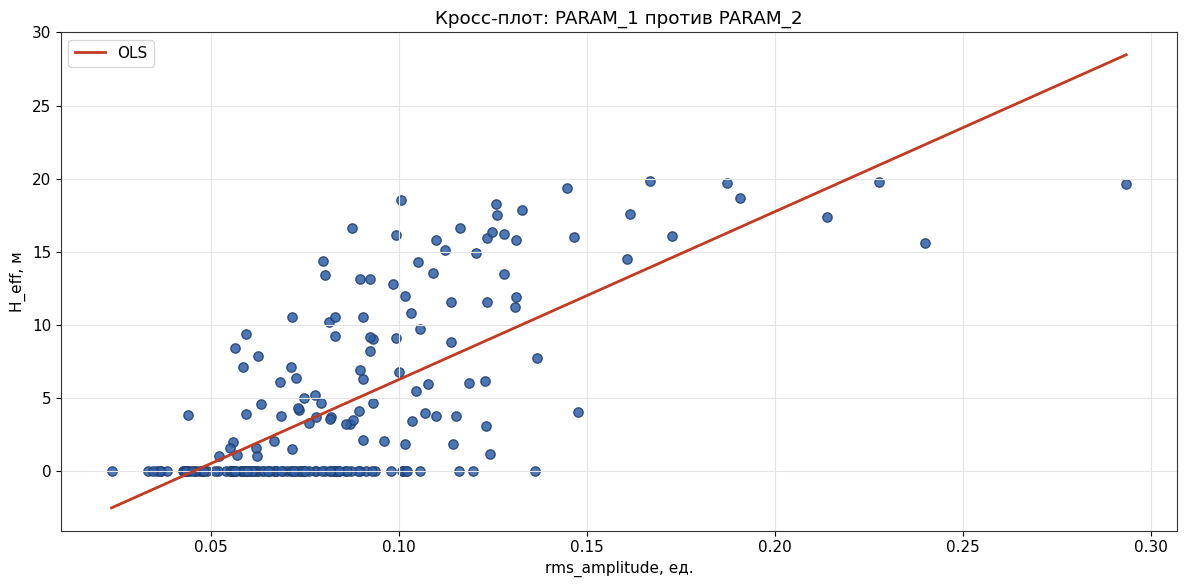

In [47]:
fig, ax = plt.subplots(figsize=(12, 6))
xl = f"{PARAM_2}, {PARAM_2_UNIT}"
yl = f"{PARAM_1}, {PARAM_1_UNIT}"

lo = df[["Zprm_well", "Zprm_map"]].min().min()
hi = df[["Zprm_well", "Zprm_map"]].max().max()
#ax.plot([lo, hi], [lo, hi], "--", color="#999", label="Y = X")
ax.scatter(df["Zprm_map"], df["Zprm_well"], c=BLUE, edgecolor="#1F3F70", s=45, alpha=.85)
xs = np.linspace(df["Zprm_map"].min(), df["Zprm_map"].max(), 100)
ax.plot(xs, basic.intercept + basic.slope * xs, color=RED, lw=2, label="OLS")
ax.set_xlabel(xl); ax.set_ylabel(yl)
ax.set_title("Кросс-плот: PARAM_1 против PARAM_2")
ax.legend()
plt.tight_layout()
plt.show()


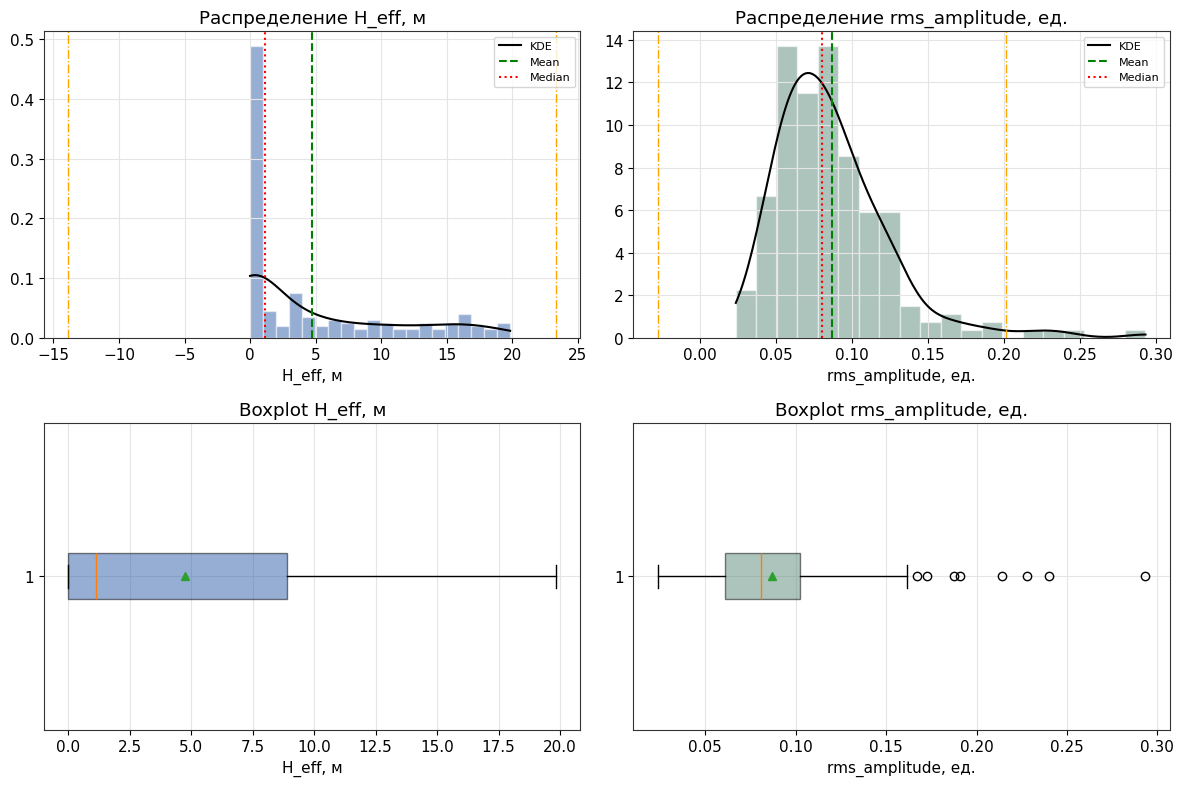

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for j, (col, label, colr) in enumerate([("Zprm_well", f"{PARAM_1}, {PARAM_1_UNIT}", BLUE),
                                         ("Zprm_map", f"{PARAM_2}, {PARAM_2_UNIT}", "#5C8A7A")]):
    s = df[col].to_numpy(float)
    ax = axes[0, j]
    ax.hist(s, bins=20, density=True, color=colr, alpha=.5, edgecolor="white")
    xs = np.linspace(s.min(), s.max(), 200)
    ax.plot(xs, gaussian_kde(s)(xs), color="black", label="KDE")
    m, md, sd = s.mean(), np.median(s), s.std(ddof=1)
    ax.axvline(m, color="green", ls="--", label="Mean")
    ax.axvline(md, color="red", ls=":", label="Median")
    for k in (-3, 3):
        ax.axvline(m + k * sd, color="orange", ls="-.", lw=1)
    ax.set_title(f"Распределение {label}"); ax.set_xlabel(label); ax.legend(fontsize=8)
    axes[1, j].boxplot(s, vert=False, showmeans=True, patch_artist=True,
                       boxprops=dict(facecolor=colr, alpha=.5))
    axes[1, j].set_title(f"Boxplot {label}"); axes[1, j].set_xlabel(label)
plt.tight_layout(); plt.show()


__Аппроксимации и квантильная регрессия (Шаг 1)__

На кросс-плот накладываются 17 типов кривых. Ниже — сравнительная таблица метрик для всех 17. Метрики считаются по невязке `Predicted − Actual`.

In [14]:
x = df["Zprm_map"].to_numpy(float)
y = df["Zprm_well"].to_numpy(float)

approx_list = (["Linear", "Quadratic", "Cubic"]
               + [f"Polynomial Degree {n}" for n in range(4, 11)]
               + ["Power Law", "Exponential", "Logarithmic",
                  "Robust (Huber)", "Theil-Sen", "RANSAC", "LOWESS"])   # 17 типов

rows = []
for a in approx_list:
    s = sq.compute_fit_stats(x, y, a)
    rows.append({"Аппроксимация": a, "R²_fit": s.r2, "RMSE": s.rmse,
                 "MAE": s.mae, "Bias": s.bias, "WAPE %": s.wape_pct, "Уравнение": s.equation})
pd.DataFrame(rows).round(3)


,Аппроксимация,R²_fit,RMSE,MAE,Bias,WAPE %,Уравнение
0,Linear,0.500,4.375,3.437,-0.000,72.514,y = 114.90715·x - 5.23414
1,Quadratic,0.510,4.331,3.440,0.000,72.578,y = -205.96629·x^2 + 165.06037·x - 7.73728
2,Cubic,0.527,4.253,3.231,0.000,68.169,y = -3849.29358·x^3 + 1437.17024·x^2 - 29.6950...
3,Polynomial Degree 4,0.535,4.220,3.136,0.000,66.156,y = 34556.93084·x^4 - 24439.41042·x^3 + 5504.6...
4,Polynomial Degree 5,0.536,4.214,3.125,-0.000,65.928,y = 253684.07751·x^5 - 154820.61872·x^4 + 2689...
5,Polynomial Degree 6,0.536,4.214,3.121,0.000,65.843,y = 1295304.62820·x^6 - 887348.89605·x^5 + 232...
6,Polynomial Degree 7,0.536,4.212,3.126,-0.000,65.949,y = 37952180.62045·x^7 - 36972252.27610·x^6 + ...
7,Polynomial Degree 8,0.536,4.212,3.124,-0.000,65.903,y = 109089910.76712·x^8 - 86541741.87986·x^7 +...
8,Polynomial Degree 9,0.536,4.212,3.125,0.000,65.926,y = -4652065954.44781·x^9 + 6032610192.56064·x...
9,Polynomial Degree 10,0.537,4.211,3.131,0.000,66.060,y = 213238151473.69391·x^10 - 304100520799.481...


In [15]:
q_rows = []
for tau in [0.1, 0.5, 0.9]:
    s = sq.compute_quantile_stats(x, y, tau)
    q_rows.append({"τ": tau, "R²_fit": s.r2, "RMSE": s.rmse,
                   "MAE": s.mae, "Bias": s.bias, "Уравнение": s.equation})
pd.DataFrame(q_rows).round(3)


,τ,R²_fit,RMSE,MAE,Bias,Уравнение
0,0.1,-0.587,7.793,4.740,-4.740,y = 0.00002·x + -0.00000
1,0.5,0.482,4.453,3.385,-0.757,y = 105.65614·x + -5.18772
2,0.9,-0.595,7.812,6.562,6.179,y = 165.54254·x + -3.45043


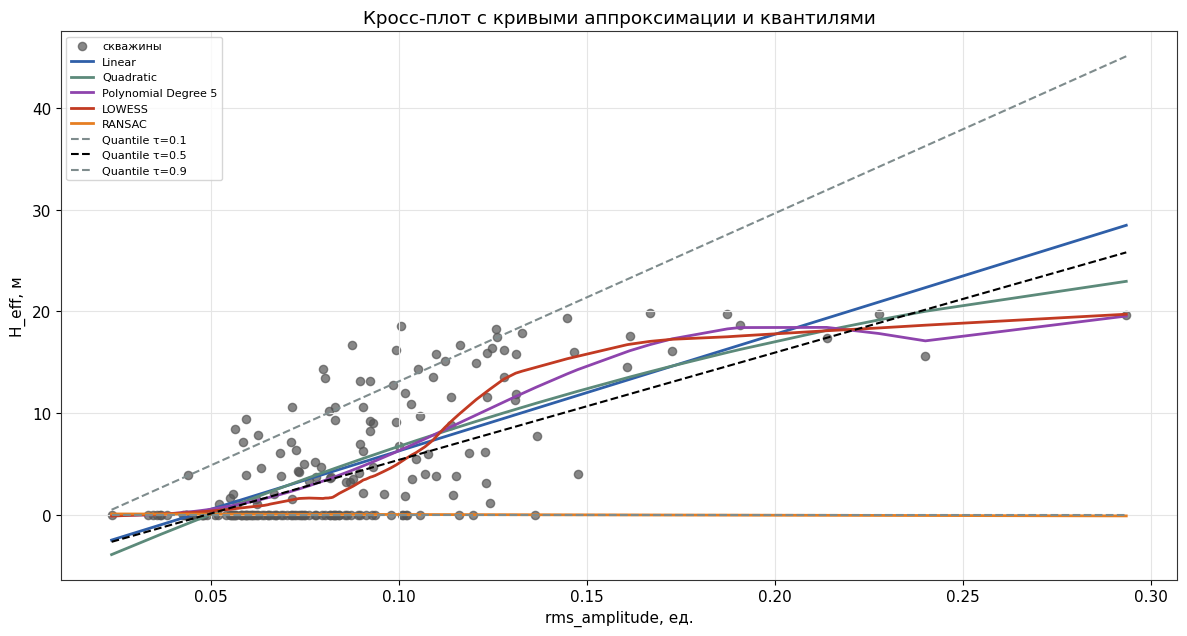

In [48]:
order = np.argsort(x)
fig, ax = plt.subplots(figsize=(12, 6.5))
ax.scatter(x, y, s=35, c="#555", alpha=.7, label="скважины")
lo, hi = min(x.min(), y.min()), max(x.max(), y.max())
#ax.plot([lo, hi], [lo, hi], "--", color="#999", label="Y = X")
# FitStats.residuals = Predicted − Actual, поэтому Predicted = residuals + y
for a, colr in [("Linear", BLUE), ("Quadratic", "#5C8A7A"), ("Polynomial Degree 5", "#8E44AD"),
                ("LOWESS", RED), ("RANSAC", "#E67E22")]:
    s = sq.compute_fit_stats(x, y, a)
    ax.plot(x[order], (s.residuals + y)[order], color=colr, lw=2, label=a)
for tau, colr in [(0.1, "#7F8C8D"), (0.5, "black"), (0.9, "#7F8C8D")]:
    s = sq.compute_quantile_stats(x, y, tau)
    ax.plot(x[order], (s.residuals + y)[order], ls="--", color=colr, lw=1.5, label=f"Quantile τ={tau}")
ax.set_xlabel(f"{PARAM_2}, {PARAM_2_UNIT}"); ax.set_ylabel(f"{PARAM_1}, {PARAM_1_UNIT}")
ax.set_title("Кросс-плот с кривыми аппроксимации и квантилями")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()


**Важно:** для τ = 0.1 и 0.9 R²_fit может быть отрицательным. Квантильная регрессия описывает границы разброса, поэтому такие кривые оцениваются по уравнению и Bias, а не по R².

<div class="alert alert-info">
  <b> * <a href="#ch8">к содержанию</a> </b>
</div>

---

## Шаг 2: __Кросс-валидация__ <a class="anchor" id="ch8_3"></a>

Модель: `PARAM_1 = a + b·PARAM_2`, обучаемая по части скважин и проверяемая на остальных. Запускаются все схемы из раздела «Типы кросс-валидации». Схема Stratified by Zone пропускается, если колонки зоны нет или в ней меньше двух значений.

Random K-Fold включён как заведомо оптимистичная база и участвует в выборе лучшей схемы. Это известное ограничение: если вывод зависит от него, выбор лучшей схемы стоит перепроверить без Random K-Fold.


### Автоматические рекомендации параметров CV

Значения рассчитываются по числу скважин и медианному расстоянию между ними. Их можно скорректировать вручную (в приложении — слайдерами в сайдбаре).

In [17]:
coords = df[["X_coord", "Y_coord"]].to_numpy(float)
y_true = df["Zprm_well"].to_numpy(float)
n_wells = df["well_id"].nunique()
median_dist = float(np.median(pdist(coords)))

def recommend_cv(n, md):
    return {
        "k (Random K-Fold)": 5 if n < 20 else 7 if n < 50 else 10 if n < 150 else 12,
        "grid_n (Block/Buffered)": 5 if md < 300 else 4 if md < 600 else 3 if md < 1000 else 2,
        "buffer, м (Buffered)": 0.5 * md,
        "cv_repeats (Leave-P-Out)": 100 if n < 30 else 50 if n < 100 else 30 if n < 300 else 20,
        "radius, м (Spatial LPO)": md,
    }

print(f"скважин: {n_wells}, медианное расстояние между скважинами: {median_dist:.0f} м")
pd.Series(recommend_cv(n_wells, median_dist), name="рекомендовано").round(1).to_frame()


скважин: 100, медианное расстояние между скважинами: 5657 м


,рекомендовано
k (Random K-Fold),10.0
grid_n (Block/Buffered),2.0
"buffer, м (Buffered)",2828.7
cv_repeats (Leave-P-Out),30.0
"radius, м (Spatial LPO)",5657.5


### Радиус исключения в Distance-based exclusion CV

Радиус = медианное попарное расстояние × множитель `variogram_factor`. Таблица показывает, как меняется RMSE при разных множителях. Большой множитель означает более строгое исключение соседей.

In [18]:
rows = []
for f in [0.5, 1.0, 1.5, 2.0, 3.0]:
    preds, _ = sq.cv_distance_exclusion(df, degree=1, variogram_factor=f)
    m = ~np.isnan(preds)
    rows.append({"variogram_factor": f,
                 "радиус исключения, м": sq.median_pairwise_distance(coords) * f,
                 "RMSE": np.sqrt(np.mean((preds[m] - y_true[m]) ** 2)),
                 "скважин с прогнозом": int(m.sum())})
pd.DataFrame(rows).round(3)


E:\envs\py310\lib\site-packages\numpy\core\fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
E:\envs\py310\lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


,variogram_factor,"радиус исключения, м",RMSE,скважин с прогнозом
0,0.5,2828.737,4.417,200
1,1.0,5657.474,4.385,200
2,1.5,8486.211,4.312,174
3,2.0,11314.949,4.436,58
4,3.0,16972.423,NaN,0


### Сравнение схем CV

Сравнительная таблица по всем схемам, RMSE по схемам, средний RMSE по фолдам, разброс RMSE по фолдам и выбор лучшей схемы по `score = RMSE + RMSE_fold_std`.

In [19]:
results, comparison = sq.run_all_cv(df, degree=1, k=5, grid_n=3, strat_zone_col="tectonic_zone")
comparison.round(3)


,n_pred,n_test_min,n_test_max,r2_actual_pred,rmse,mae,bias,rmse_fold_mean,rmse_fold_median,rmse_fold_min,rmse_fold_max,rmse_fold_std,rmse_fold_range
CV scheme,,,,,,,,,,,,,
Random K-Fold,200.0,40.0,40.0,0.490,4.416,3.476,0.002,4.399,4.308,3.892,4.996,0.435,1.104
Random K-Fold (buffered),200.0,40.0,40.0,0.492,4.410,3.465,0.007,4.391,4.307,3.834,5.000,0.457,1.166
Leave-One-Well-Out,200.0,2.0,2.0,0.489,4.422,3.470,0.006,3.907,3.502,0.326,8.925,2.082,8.598
Block CV,200.0,6.0,28.0,0.494,4.400,3.450,0.007,4.337,4.330,3.214,5.111,0.602,1.897
Buffered CV,200.0,6.0,28.0,0.494,4.400,3.450,0.007,4.337,4.330,3.214,5.111,0.602,1.897
Leave-P-Out,200.0,20.0,20.0,0.487,4.431,3.478,-0.005,4.357,4.412,2.473,6.127,0.796,3.653
Spatial Leave-P-Out,152.0,2.0,12.0,0.500,4.469,3.447,-0.121,4.213,4.305,1.555,6.299,1.218,4.744
Stratified by tectonic_zone,200.0,52.0,76.0,0.494,4.400,3.446,-0.041,4.315,4.037,3.786,5.121,0.709,1.334
Distance-based exclusion CV,200.0,1.0,1.0,0.497,4.385,3.428,0.105,3.428,2.791,0.021,12.442,2.742,12.421


In [20]:
comparison = comparison.copy()
comparison["score"] = comparison["rmse"] + comparison["rmse_fold_std"]
# Выбор как в приложении: min по всем схемам, включая Random K-Fold (известное ограничение)
best = comparison["score"].idxmin()
print(f"Лучшая схема по score = RMSE + RMSE_fold_std: {best}")
comparison.sort_values("score")[["rmse", "rmse_fold_std", "score"]].round(3)


Лучшая схема по score = RMSE + RMSE_fold_std: Random K-Fold


,rmse,rmse_fold_std,score
CV scheme,,,
Random K-Fold,4.416,0.435,4.851
Random K-Fold (buffered),4.410,0.457,4.867
Block CV,4.400,0.602,5.003
Buffered CV,4.400,0.602,5.003
Stratified by tectonic_zone,4.400,0.709,5.110
Leave-P-Out,4.431,0.796,5.227
Spatial Leave-P-Out,4.469,1.218,5.687
Leave-One-Well-Out,4.422,2.082,6.504
Distance-based exclusion CV,4.385,2.742,7.128


In [21]:
print("Схемы с разным числом прогнозов (n_pred):", comparison["n_pred"].nunique() > 1)
print(comparison["n_pred"].astype(int).to_string())
skipped = {name: int(r["folds"]["fold"].astype(str).str.contains("skipped").sum())
           for name, r in results.items() if r.get("folds") is not None and len(r["folds"])}
print("Пропущенных фолдов по схемам:", {k: v for k, v in skipped.items() if v})


Схемы с разным числом прогнозов (n_pred): True
CV scheme
Random K-Fold                  200
Random K-Fold (buffered)       200
Leave-One-Well-Out             200
Block CV                       200
Buffered CV                    200
Leave-P-Out                    200
Spatial Leave-P-Out            152
Stratified by tectonic_zone    200
Distance-based exclusion CV    200
Пропущенных фолдов по схемам: {}


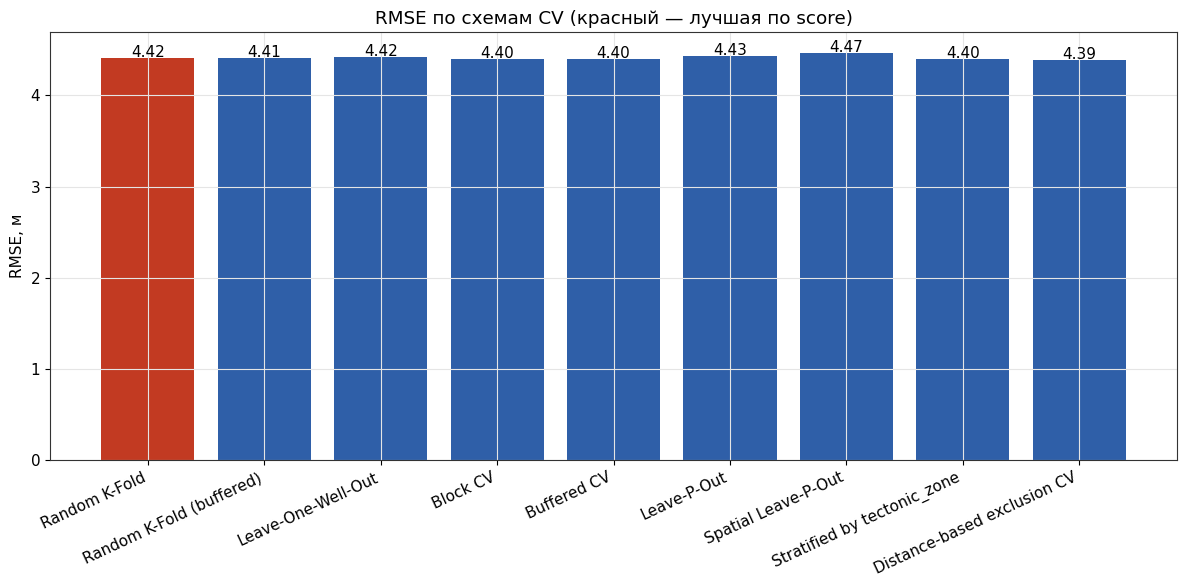

Random K-Fold RMSE = 4.416, наихудшая из пространственных схем = 4.469 (разница 0.053: мера оптимизма случайного разбиения)


In [45]:
fig, ax = plt.subplots(figsize=(12, 6))
colors = [RED if i == best else ("#999999" if i == "Random K-Fold" else BLUE)
          for i in comparison.index]
bars = ax.bar(comparison.index, comparison["rmse"], color=colors)
for b, v in zip(bars, comparison["rmse"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center")
ax.set_ylabel(f"RMSE, {PARAM_1_UNIT}")
ax.set_title("RMSE по схемам CV (красный — лучшая по score)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

gap = comparison.loc["Random K-Fold", "rmse"]
worst = comparison.drop(index="Random K-Fold")["rmse"].max()
print(f"Random K-Fold RMSE = {gap:.3f}, наихудшая из пространственных схем = {worst:.3f} "
      f"(разница {worst - gap:.3f}: мера оптимизма случайного разбиения)")


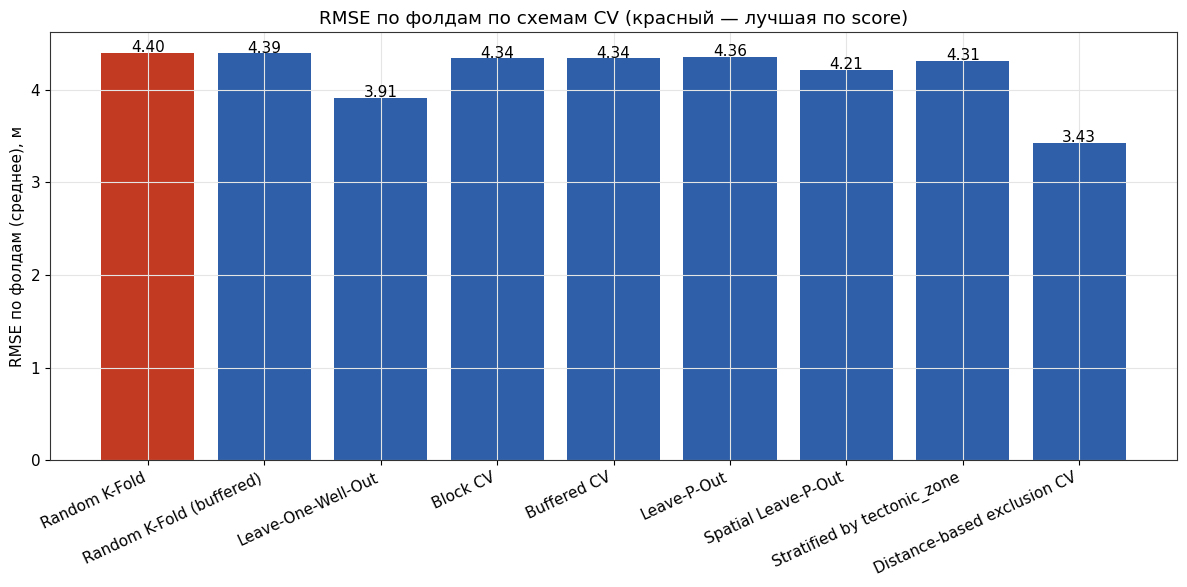

In [49]:
fig, ax = plt.subplots(figsize=(12, 6))
colors = [RED if i == best else ("#999999" if i == "Random K-Fold" else BLUE)
          for i in comparison.index]
bars = ax.bar(comparison.index, comparison["rmse_fold_mean"], color=colors)
for b, v in zip(bars, comparison["rmse_fold_mean"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center")
ax.set_ylabel(f"RMSE по фолдам (среднее), {PARAM_1_UNIT}")
ax.set_title("RMSE по фолдам по схемам CV (красный — лучшая по score)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


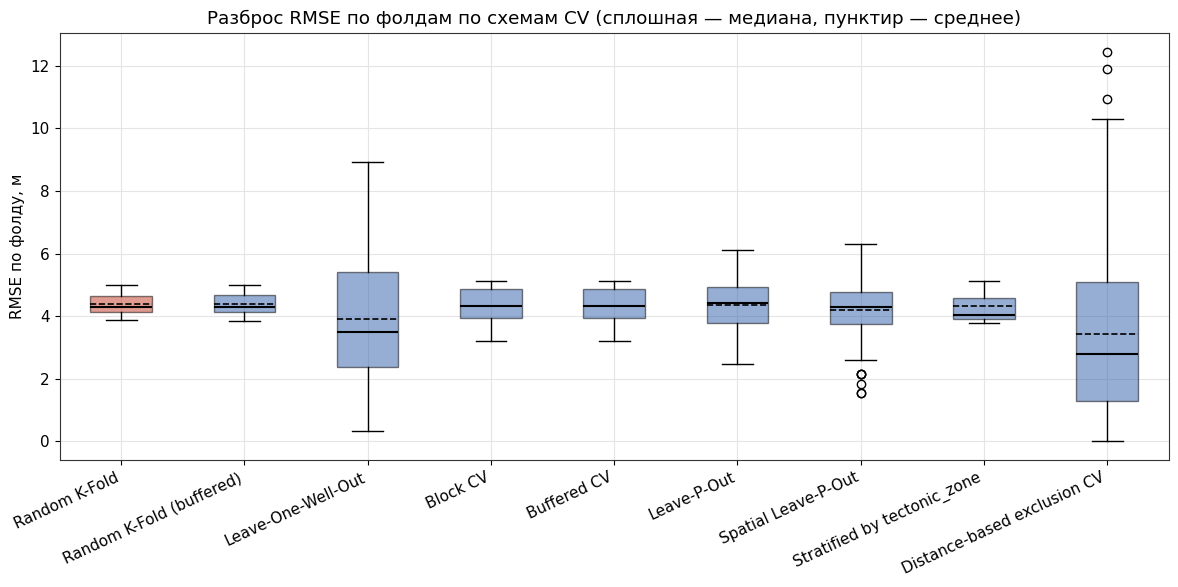

In [50]:
# Boxplot разброса RMSE по фолдам: медиана — сплошная, среднее — пунктир
labels, data, colors = [], [], []
for name in comparison.index:
    f = results[name].get("folds")
    vals = f["rmse"].dropna().to_numpy(float) if f is not None and len(f) else np.array([])
    if len(vals) == 0:
        continue
    labels.append(name)
    data.append(vals)
    colors.append(RED if name == best else ("#999999" if name == "Random K-Fold" else BLUE))

fig, ax = plt.subplots(figsize=(12, 6))
bp = ax.boxplot(data, patch_artist=True, showmeans=True, meanline=True,
                medianprops=dict(color="black", linewidth=1.5),
                meanprops=dict(color="black", linestyle="--", linewidth=1.2))
for patch, c in zip(bp["boxes"], colors):
    patch.set_facecolor(c)
    patch.set_alpha(0.5)
ax.set_xticks(range(1, len(labels) + 1))
ax.set_xticklabels(labels, rotation=25, ha="right")
ax.set_ylabel(f"RMSE по фолду, {PARAM_1_UNIT}")
ax.set_title("Разброс RMSE по фолдам по схемам CV (сплошная — медиана, пунктир — среднее)")
plt.tight_layout()
plt.show()


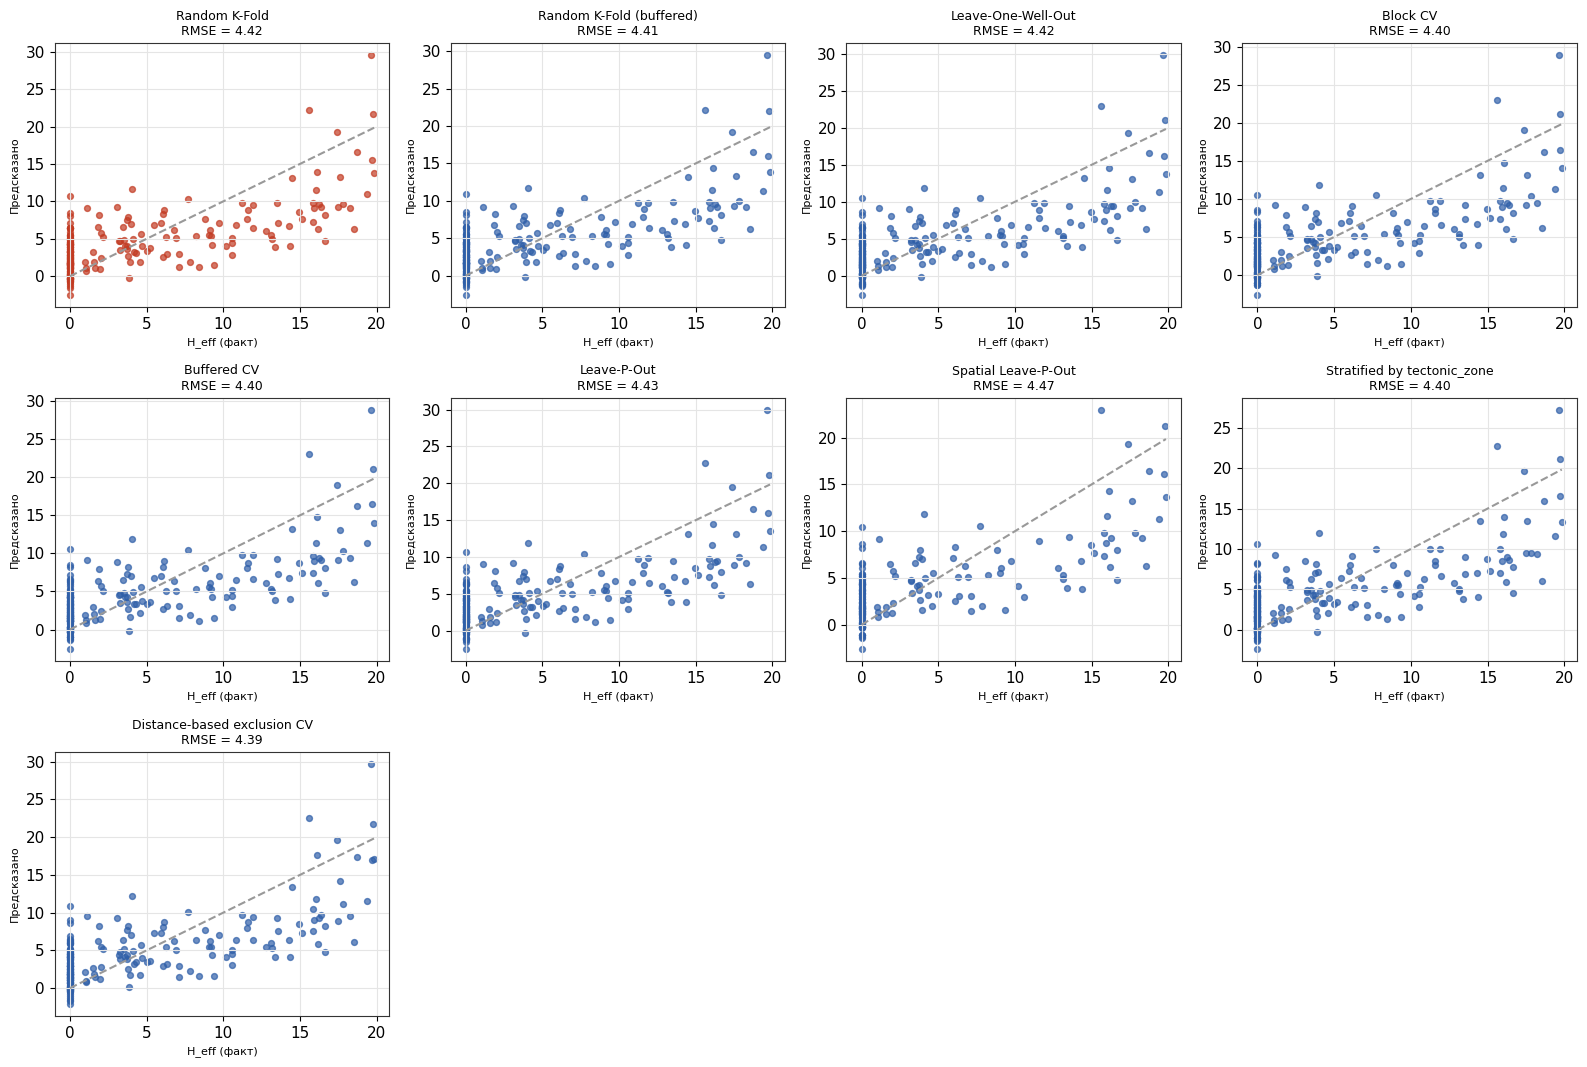

In [25]:
names = list(comparison.index)
ncol = 4
nrow = int(np.ceil(len(names) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 3.6 * nrow), squeeze=False)
for ax, name in zip(axes.ravel(), names):
    p = results[name]["preds"]
    m = ~np.isnan(p)
    ax.scatter(y_true[m], p[m], s=18, alpha=.7, color=RED if name == best else BLUE)
    lo_, hi_ = y_true.min(), y_true.max()
    ax.plot([lo_, hi_], [lo_, hi_], "--", color="#999")
    ax.set_title(f"{name}\nRMSE = {comparison.loc[name, 'rmse']:.2f}", fontsize=9)
    ax.set_xlabel(f"{PARAM_1} (факт)", fontsize=8); ax.set_ylabel("Предсказано", fontsize=8)
for ax in axes.ravel()[len(names):]:
    ax.axis("off")
plt.tight_layout(); plt.show()


In [26]:
def detect_outliers(r, sigma_thr=2.0, iqr_k=1.5, pct_low=5.0, pct_high=95.0):
    """Четыре правила выбросов по невязкам. Применяются к CV-невязкам шага 2."""
    r = np.asarray(r, dtype=float)
    med = np.median(r)
    sd = r.std(ddof=1)
    q25, q75 = np.quantile(r, [0.25, 0.75])
    q05, q95 = np.quantile(r, [pct_low / 100, pct_high / 100])
    iqr = q75 - q25
    mad = np.median(np.abs(r - med))
    modz = 0.6745 * (r - med) / mad if mad > 0 else np.zeros_like(r)
    return {
        "sigma": np.abs(r) > sigma_thr * sd,
        "IQR": (r < q25 - iqr_k * iqr) | (r > q75 + iqr_k * iqr),
        "modified z": np.abs(modz) > 3.5,
        "P05–P95": (r < q05) | (r > q95),
    }


### Детальный разбор лучшей схемы

Predicted против Actual для лучшей схемы, распределение CV-невязок (PARAM_1 − Predicted) и выбросы по четырём правилам.

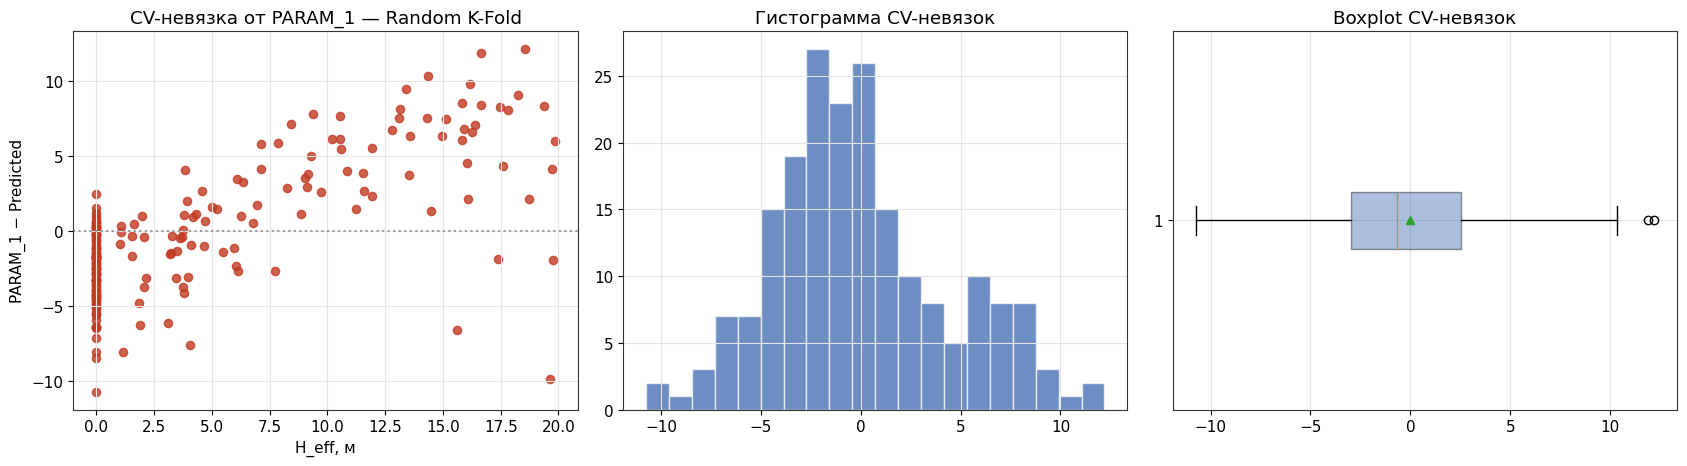

,CV-невязка
Count,200.000
μ (mean),-0.002
median,-0.673
mode,-8.040
σ (std),4.427
variance,19.601
"CV, %",-291697.082
min,-10.742
Q05,-6.412
Q25,-2.972


выбросы по методам: {'sigma': 8, 'IQR': 2, 'modified z': 0, 'P05–P95': 20}


In [27]:
best_preds = results[best]["preds"]
m = ~np.isnan(best_preds)
cv_res = y_true[m] - best_preds[m]            # PARAM_1 − Predicted (как на графике CV-невязок)
p1 = y_true[m]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
axes[0].scatter(p1, cv_res, s=35, color=RED, alpha=.8)
axes[0].axhline(0, ls=":", color="#999")
axes[0].set_xlabel(f"{PARAM_1}, {PARAM_1_UNIT}"); axes[0].set_ylabel("PARAM_1 − Predicted")
axes[0].set_title(f"CV-невязка от PARAM_1 — {best}")
axes[1].hist(cv_res, bins=20, color=BLUE, alpha=.7, edgecolor="white")
axes[1].set_title("Гистограмма CV-невязок")
axes[2].boxplot(cv_res, vert=False, showmeans=True, patch_artist=True,
                boxprops=dict(facecolor=BLUE, alpha=.4))
axes[2].set_title("Boxplot CV-невязок")
plt.tight_layout(); plt.show()

display(pd.DataFrame({"CV-невязка": param_stats(cv_res)}).round(3))
cv_m = detect_outliers(cv_res)
print("выбросы по методам:", {k: int(v.sum()) for k, v in cv_m.items()})


### Разбор по фолдам и зонам (Шаг 2, детально)

Предсказание против факта с разбивкой по тектоническим зонам. Зона, где разброс систематически больше, — кандидат на проблему связи атрибута, на зону разломов или на потерю когерентности сейсмики. Конкретный вывод зависит от данных.

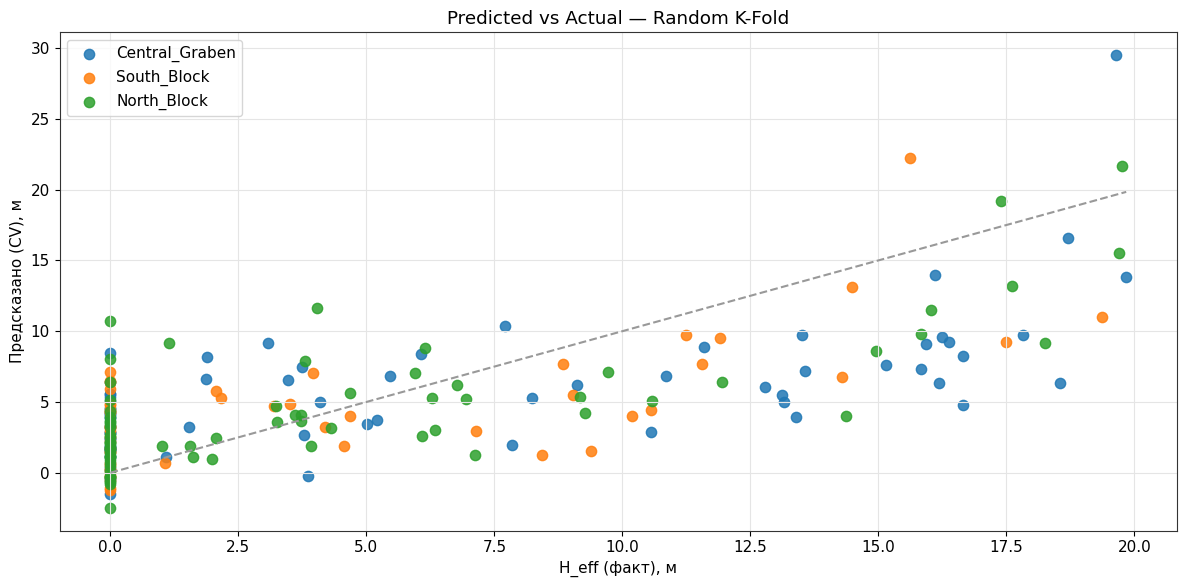

In [51]:
fig, ax = plt.subplots(figsize=(12, 6))
preds = results[best]["preds"]
zones = df["tectonic_zone"] if "tectonic_zone" in df.columns else pd.Series("all", index=df.index)
palette = plt.cm.tab10.colors
for i, zone in enumerate(zones.unique()):
    m = (zones == zone).to_numpy()
    ax.scatter(df.loc[m, "Zprm_well"], preds[m], label=str(zone), s=55, alpha=.85,
               color=palette[i % len(palette)])
lo, hi = df["Zprm_well"].min(), df["Zprm_well"].max()
ax.plot([lo, hi], [lo, hi], "--", color="#999")
ax.set_xlabel(f"{PARAM_1} (факт), {PARAM_1_UNIT}"); ax.set_ylabel(f"Предсказано (CV), {PARAM_1_UNIT}")
ax.legend(); ax.set_title(f"Predicted vs Actual — {best}")
plt.tight_layout()
plt.show()


__Выбросы в кросс-валидации (LOWO)__

In [29]:
preds_lowo = results["Leave-One-Well-Out"]["preds"]
cv_resid = df["Zprm_well"].to_numpy() - preds_lowo      # PARAM_1 − Predicted
cv_masks = detect_outliers(cv_resid)
print({k: int(v.sum()) for k, v in cv_masks.items()})

sel = cv_masks["sigma"]
out_cv = df.loc[sel, ["well_id", "X_coord", "Y_coord", "Zprm_well"]].copy()
out_cv["Predicted_LOWO"] = preds_lowo[sel]
out_cv["Residual"] = cv_resid[sel]
out_cv


{'sigma': 8, 'IQR': 2, 'modified z': 0, 'P05–P95': 20}


,well_id,X_coord,Y_coord,Zprm_well,Predicted_LOWO,Residual
35,W-036,2407.3,4444.8,18.25,9.187686,9.062314
53,W-054,4651.6,7170.9,19.64,29.802264,-10.162264
70,W-071,8061.2,4658.4,13.40,3.983870,9.416130
73,W-074,7946.6,1838.9,18.55,6.280110,12.269890
74,W-075,1579.4,618.7,14.37,3.879748,10.490252
85,W-086,7698.9,466.5,16.66,4.789767,11.870233
92,W-093,5612.8,389.9,16.18,6.153500,10.026500
121,W-022,1922.5,6284.6,0.00,10.558217,-10.558217


<div class="alert alert-info">
  <b> * <a href="#ch8">к содержанию</a> </b>
</div>

---

## Шаг 3: __Диагностика по категориям__ <a class="anchor" id="ch8_4"></a>

Та же пара параметров, но по категориальной колонке: тектоническая зона, горизонт, тип коллектора, тип флюида. Для каждой категории считаются статистика параметров, линейная аппроксимация и метрики. Сравнение категорий показывает, где атрибут работает, а где нет.

In [30]:
cat_cols = [c for c in ["tectonic_zone", "horizon_id", "reservoir_flag", "fluid_type", "quality_flag"]
            if c in df.columns and df[c].nunique() >= 2]

for col in cat_cols:
    rows = []
    for k, d in df.groupby(col):
        row = {col: k, "n": len(d)}
        if len(d) >= 3:
            try:
                s = sq.compute_fit_stats(d["Zprm_map"].to_numpy(float), d["Zprm_well"].to_numpy(float), "Linear")
                row.update({"R²_fit": s.r2, "RMSE": s.rmse, "Bias": s.bias, "Уравнение": s.equation})
            except ValueError as e:
                row["примечание"] = str(e)
        rows.append(row)
    print(f"--- линейная аппроксимация по {col} ---")
    display(pd.DataFrame(rows).round(3))

    stat_rows = []
    for k, d in df.groupby(col):
        stat_rows.append({col: k, "n": len(d),
                          f"{PARAM_1} μ": d["Zprm_well"].mean(), f"{PARAM_1} σ": d["Zprm_well"].std(ddof=1),
                          f"{PARAM_2} μ": d["Zprm_map"].mean(), f"{PARAM_2} σ": d["Zprm_map"].std(ddof=1)})
    display(pd.DataFrame(stat_rows).round(3))


--- линейная аппроксимация по tectonic_zone ---


,tectonic_zone,n,R²_fit,RMSE,Bias,Уравнение
0,Central_Graben,76,0.451,5.057,-0.0,y = 120.08124·x - 5.29256
1,North_Block,72,0.574,3.765,0.0,y = 112.65820·x - 5.29444
2,South_Block,52,0.477,4.003,0.0,y = 106.25345·x - 4.77983


,tectonic_zone,n,H_eff μ,H_eff σ,rms_amplitude μ,rms_amplitude σ
0,Central_Graben,76,5.727,6.871,0.092,0.038
1,North_Block,72,4.220,5.809,0.084,0.039
2,South_Block,52,4.017,5.592,0.083,0.036


--- линейная аппроксимация по horizon_id ---


,horizon_id,n,R²_fit,RMSE,Bias,Уравнение
0,Top_Reservoir,100,0.536,4.295,-0.0,y = 112.76410·x - 3.50894
1,Top_Seal,100,0.526,3.883,0.0,y = 116.99453·x - 6.95308


...

,reservoir_flag,n,R²_fit,RMSE,Bias,Уравнение
0,non_reservoir,97,1.000,0.00,0.0,y = 0.00000·x + 0.00000
1,reservoir,103,0.412,4.42,-0.0,y = 89.77739·x - 0.25599


,reservoir_flag,n,H_eff μ,H_eff σ,rms_amplitude μ,rms_amplitude σ
0,non_reservoir,97,0.000,0.000,0.067,0.021
1,reservoir,103,9.203,5.792,0.105,0.041


--- линейная аппроксимация по fluid_type ---


,fluid_type,n,R²_fit,RMSE,Bias,Уравнение
0,gas,22,0.589,3.737,0.0,y = 126.89450·x - 1.15993
1,non_reservoir,97,1.000,0.000,0.0,y = 0.00000·x + 0.00000
2,oil,42,0.443,4.339,0.0,y = 82.39023·x + 0.04860
3,water,39,0.401,4.059,0.0,y = 89.68706·x - 1.29892


,fluid_type,n,H_eff μ,H_eff σ,rms_amplitude μ,rms_amplitude σ
0,gas,22,11.592,5.963,0.100,0.036
1,non_reservoir,97,0.000,0.000,0.067,0.021
2,oil,42,9.057,5.884,0.109,0.048
3,water,39,8.014,5.314,0.104,0.038


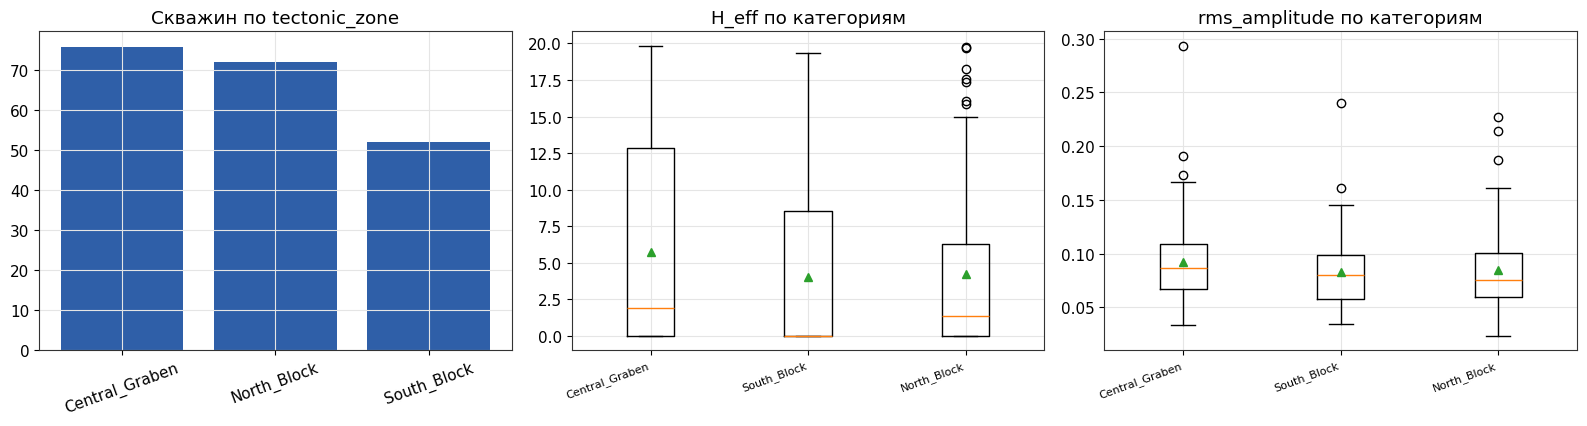

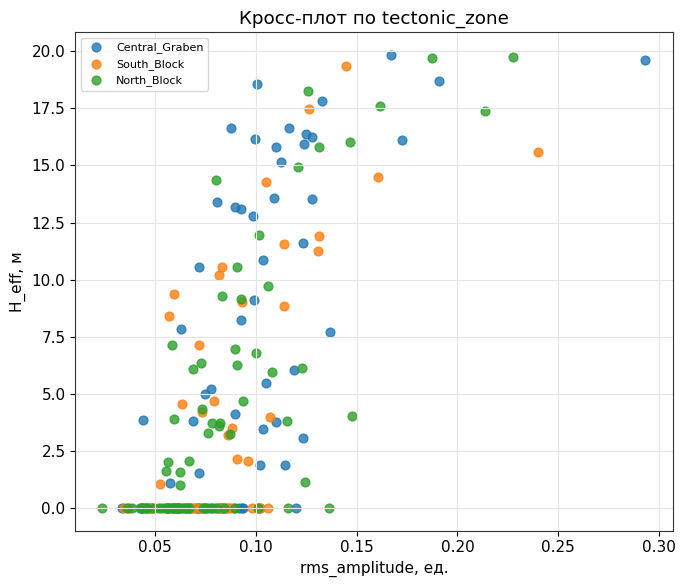

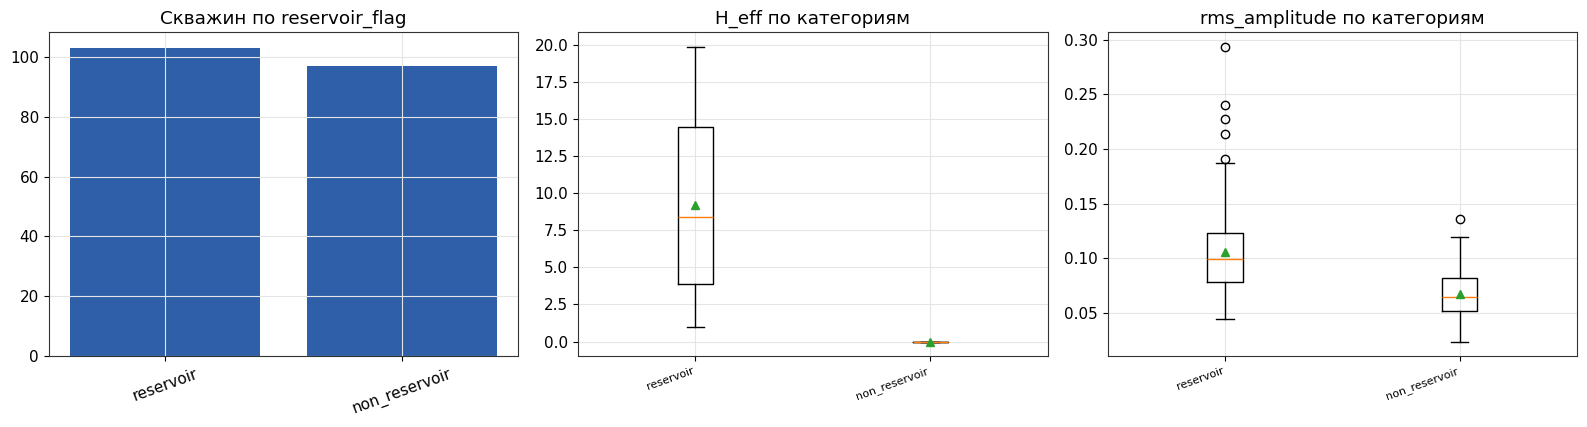

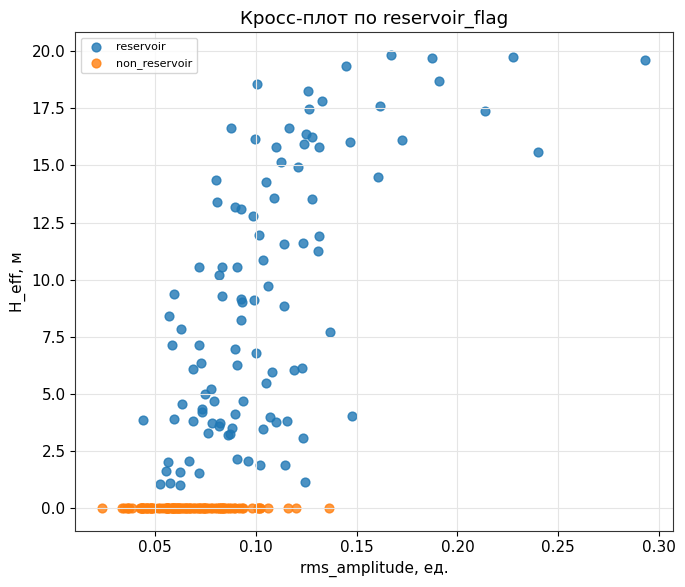

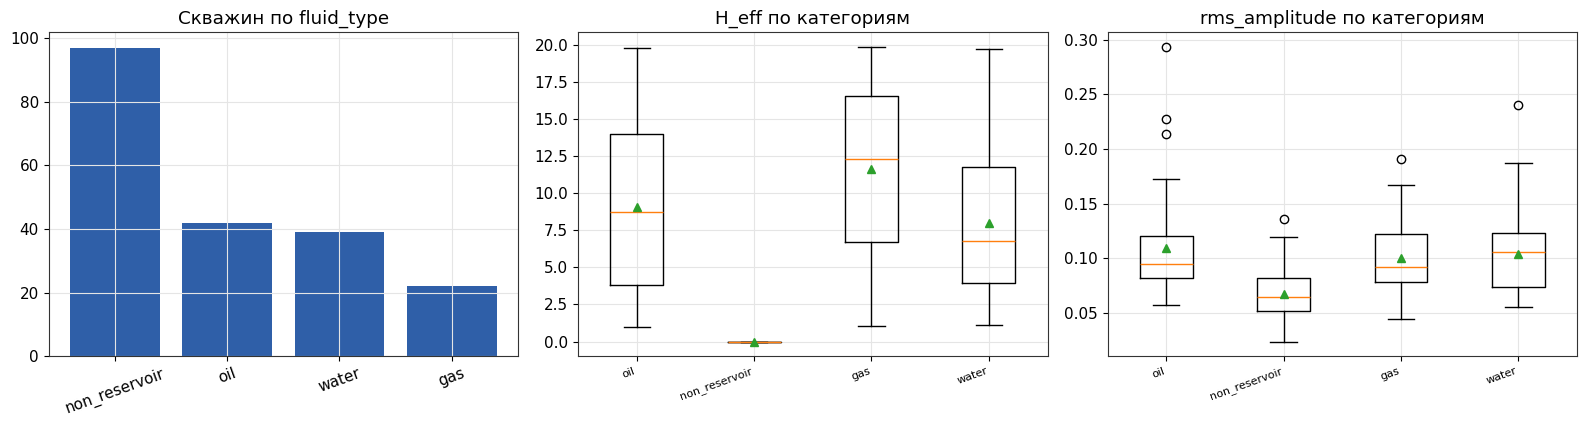

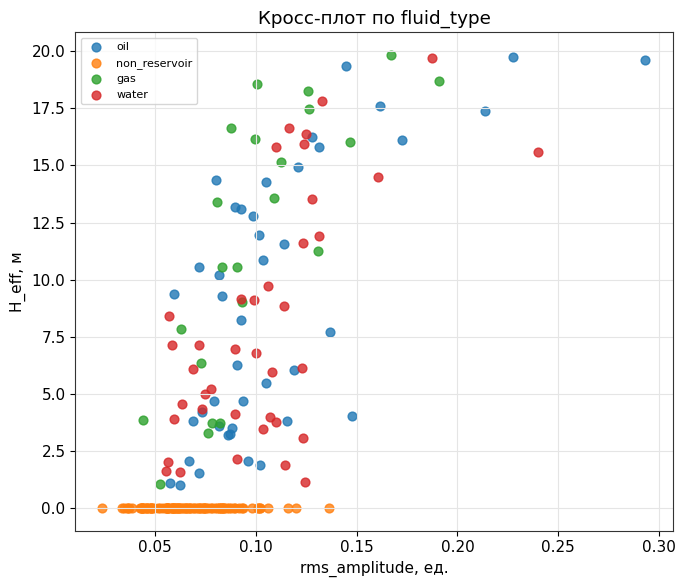

In [31]:
for col in [c for c in ["tectonic_zone", "reservoir_flag", "fluid_type"] if c in df.columns and df[c].nunique() >= 2]:
    cats = list(df[col].dropna().unique())

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
    cnt = df[col].value_counts()
    axes[0].bar(cnt.index.astype(str), cnt.values, color=BLUE)
    axes[0].set_title(f"Скважин по {col}")
    axes[0].tick_params(axis="x", rotation=20)
    for ax, pcol, lbl in [(axes[1], "Zprm_well", PARAM_1), (axes[2], "Zprm_map", PARAM_2)]:
        ax.boxplot([df.loc[df[col] == c, pcol] for c in cats], showmeans=True)
        ax.set_xticks(range(1, len(cats) + 1))
        ax.set_xticklabels([str(c) for c in cats], rotation=20, ha="right", fontsize=8)
        ax.set_title(f"{lbl} по категориям")
    plt.tight_layout(); plt.show()

    fig, ax = plt.subplots(figsize=(7, 6))
    for i, c in enumerate(cats):
        m = (df[col] == c).to_numpy()
        ax.scatter(df.loc[m, "Zprm_map"], df.loc[m, "Zprm_well"], s=40, alpha=.8,
                   color=plt.cm.tab10.colors[i % 10], label=str(c))
    ax.set_xlabel(f"{PARAM_2}, {PARAM_2_UNIT}"); ax.set_ylabel(f"{PARAM_1}, {PARAM_1_UNIT}")
    ax.legend(fontsize=8)
    ax.set_title(f"Кросс-плот по {col}")
    plt.tight_layout(); plt.show()


<div class="alert alert-info">
  <b> * <a href="#ch8">к содержанию</a> </b>
</div>

---

## Шаг 4: __Фильтрация скважин__ <a class="anchor" id="ch8_5"></a>

Проверяем устойчивость связи к сокращению выборки. В приложении доступны четыре режима:

- без фильтра;
- ручное исключение конкретных `well_id` (мультиселект);
- случайное исключение заданного процента (0–95%, с пересэмплированием);
- выделение точек кликом на кросс-плоте (Shift+клик, рамка Box или лассо Lasso).

В ноутбуке интерактивное выделение не воспроизводится. Рамку имитирует исключение скважин с верхними 20% значений PARAM_1.


In [32]:
rng = np.random.default_rng(42)
wells = df["well_id"].unique()

manual_excl = list(wells[:5])                                                        # ручной список
random_excl = list(rng.choice(wells, size=int(0.2 * len(wells)), replace=False))     # 20 %
z_lo, z_hi = df["Zprm_well"].quantile([0.8, 1.0])
box_excl = list(df.loc[df["Zprm_well"].between(z_lo, z_hi), "well_id"].unique())     # «рамка»

def row(name, d):
    s = sq.basic_crossplot_stats(d)
    return {"сценарий": name, "n": s.n, "R²_lin": s.r2, "slope": s.slope,
            f"RMSE, {PARAM_1_UNIT}": s.rmse, f"Bias, {PARAM_1_UNIT}": s.bias, "p-value": s.p_value}

scen = [
    row("Без фильтра", df),
    row("Ручное: 5 скважин", df[~df["well_id"].isin(manual_excl)]),
    row("Случайно: 20 %", df[~df["well_id"].isin(random_excl)]),
    row("Рамка: верхние 20 % по PARAM_1", df[~df["well_id"].isin(box_excl)]),
]
pd.DataFrame(scen).round(3)


,сценарий,n,R²_lin,slope,"RMSE, м","Bias, м",p-value
0,Без фильтра,200,0.500,114.907,7.719,4.653,0.000
1,Ручное: 5 скважин,190,0.515,116.712,7.846,4.742,0.000
2,Случайно: 20 %,160,0.507,115.113,8.055,5.050,0.000
3,Рамка: верхние 20 % по PARAM_1,126,0.088,38.122,3.588,1.959,0.001


In [33]:
stab = []
for seed in range(1, 6):
    r = np.random.default_rng(seed)
    excl = list(r.choice(wells, size=int(0.2 * len(wells)), replace=False))
    s = sq.basic_crossplot_stats(df[~df["well_id"].isin(excl)])
    stab.append({"seed": seed, "n": s.n, "R²_lin": s.r2, "slope": s.slope,
                 f"RMSE, {PARAM_1_UNIT}": s.rmse, f"Bias, {PARAM_1_UNIT}": s.bias})
stab = pd.DataFrame(stab)
display(stab.round(3))
print("Сводка по 5 наборам (по 20 % скважин исключено):")
stab[["R²_lin", "slope", f"RMSE, {PARAM_1_UNIT}", f"Bias, {PARAM_1_UNIT}"]].agg(["mean", "std", "min", "max"]).round(3)


,seed,n,R²_lin,slope,"RMSE, м","Bias, м"
0,1,160,0.496,124.827,7.784,4.726
1,2,160,0.543,116.247,7.577,4.458
2,3,160,0.446,107.946,7.241,4.198
3,4,160,0.538,120.068,7.984,4.999
4,5,160,0.506,117.170,7.449,4.367


Сводка по 5 наборам (по 20 % скважин исключено):


,R²_lin,slope,"RMSE, м","Bias, м"
mean,0.506,117.252,7.607,4.550
std,0.039,6.183,0.289,0.316
min,0.446,107.946,7.241,4.198
max,0.543,124.827,7.984,4.999


In [34]:
after = df[~df["well_id"].isin(random_excl)]
rows = []
for label, d in [("до фильтрации", df), ("после: случайно 20 %", after)]:
    xx = d["Zprm_map"].to_numpy(float)
    yy = d["Zprm_well"].to_numpy(float)
    for a in ["Linear", "Polynomial Degree 5", "LOWESS"]:
        s = sq.compute_fit_stats(xx, yy, a)
        rows.append({"набор": label, "n": len(d), "кривая": a, "R²_fit": s.r2,
                     "RMSE": s.rmse, "MAE": s.mae, "Bias": s.bias, "WAPE, %": s.wape_pct})
pd.DataFrame(rows).round(3)


,набор,n,кривая,R²_fit,RMSE,MAE,Bias,"WAPE, %"
0,до фильтрации,200,Linear,0.500,4.375,3.437,-0.000,72.514
1,до фильтрации,200,Polynomial Degree 5,0.536,4.214,3.125,-0.000,65.928
2,до фильтрации,200,LOWESS,0.501,4.370,3.004,-0.467,63.370
3,после: случайно 20 %,160,Linear,0.507,4.424,3.548,-0.000,69.042
4,после: случайно 20 %,160,Polynomial Degree 5,0.552,4.218,3.189,0.000,62.068
5,после: случайно 20 %,160,LOWESS,0.535,4.300,3.060,-0.301,59.552


Сравнивайте не только R² и RMSE, но и наклон и Bias. Если они заметно меняются при исключении нескольких скважин, результат зависит от отдельных наблюдений.

__Шаг 4.5: серия случайного исключения__

Для каждого уровня исключения от 5% до 95% (шаг 5%) формируется заданное число случайных наборов скважин. Для каждого набора считаются два R² (Pearson): in-sample по оставшимся скважинам и out-of-sample (линия по оставшимся, R² по исключённым). Здесь 100 наборов на уровень для краткости. В приложении по умолчанию 500, диапазон 50–2000.

In [35]:
lvl_long, lvl_summary = sq.random_exclusion_series(df, n_repeats=100, seed=42)
display(lvl_summary[["mode", "level_pct", "n_excluded", "n_remaining", "n_sets", "status", "median"]].round(3))


,mode,level_pct,n_excluded,n_remaining,n_sets,status,median
0,in,5,5,95,100,ok,0.499
1,out,5,5,95,100,ok,0.561
2,in,10,10,90,100,ok,0.499
3,out,10,10,90,100,ok,0.533
4,in,15,15,85,100,ok,0.500
5,out,15,15,85,100,ok,0.526
6,in,20,20,80,100,ok,0.503
7,out,20,20,80,100,ok,0.501
8,in,25,25,75,100,ok,0.497
9,out,25,25,75,100,ok,0.514


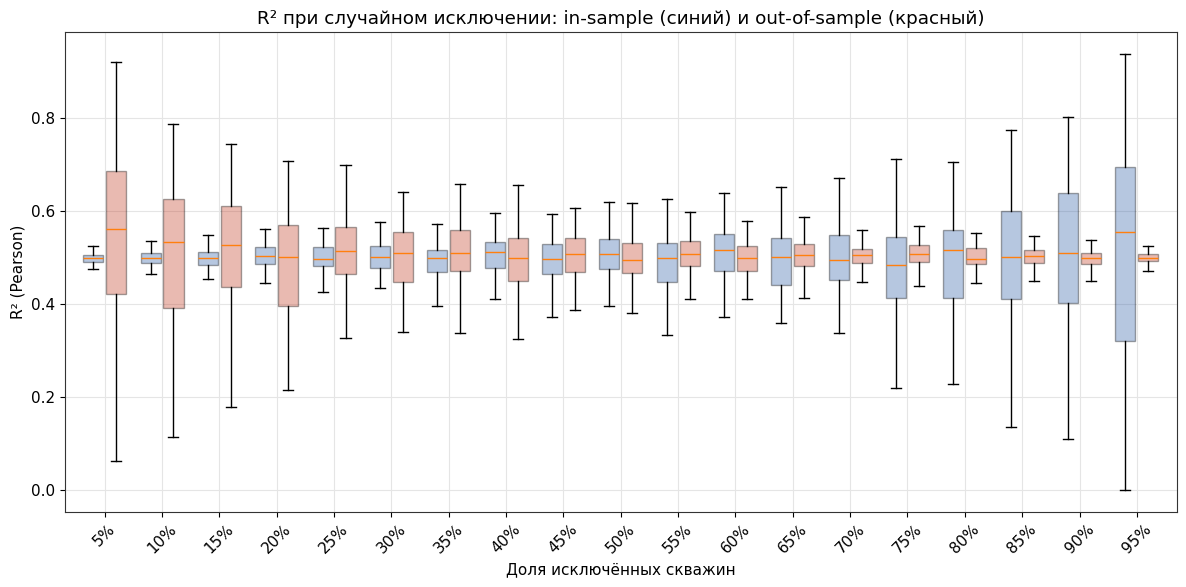

In [52]:
levels = sorted(lvl_long["level_pct"].unique())
pos = np.arange(len(levels))
fig, ax = plt.subplots(figsize=(12, 6))
for col, colr, shift in [("r2_in", BLUE, -0.2), ("r2_out", RED, 0.2)]:
    data = [lvl_long.loc[lvl_long["level_pct"] == L, col].dropna().to_numpy() for L in levels]
    bp = ax.boxplot(data, positions=pos + shift, widths=0.35, patch_artist=True, showfliers=False)
    for b in bp["boxes"]:
        b.set_facecolor(colr); b.set_alpha(.35)
ax.set_xticks(pos); ax.set_xticklabels([f"{L}%" for L in levels], rotation=45)
ax.set_xlabel("Доля исключённых скважин"); ax.set_ylabel("R² (Pearson)")
ax.set_title("R² при случайном исключении: in-sample (синий) и out-of-sample (красный)")
plt.tight_layout(); plt.show()


<div class="alert alert-info">
  <b> * <a href="#ch8">к содержанию</a> </b>
</div>

---

## Шаг 5 · Многоатрибутная регрессия <a class="anchor" id="ch8_7"></a>

Ячейка ниже запускает `step5_run` для H_eff и Phi по всем кандидатам из `ATTRIBUTES`. Результаты: одноатрибутные и многоатрибутные модели, out-of-sample метрики по схемам LOWO и K-fold, in-sample метрики и коэффициенты.

In [37]:
CANDIDATES = ATTRIBUTES
out5 = sq.step5_run(df, CANDIDATES, phi_upper=1.0, params=("H_eff", "Phi"))
print(f"ok = {out5['ok']}, скважин: {out5['n_wells']}, k_max = {out5['kmax']}, "
      f"K (K-fold) = {out5['kfold_K']}, запрещённых пар (|r| > 0.8): {out5['excluded_pairs']}")


ok = True, скважин: 100, k_max = 3, K (K-fold) = 10, запрещённых пар (|r| > 0.8): 0


In [38]:
for scheme in sq.S5_SCHEMES:
    sc5 = out5["schemes"][scheme]
    print(f"===== Схема: {scheme} =====")
    print("Одноатрибутные модели, out-of-sample:")
    display(sc5["singles"].round(3))
    print("Топ многоатрибутных моделей, out-of-sample:")
    display(sc5["table"].round(3))


===== Схема: LOWO =====
Одноатрибутные модели, out-of-sample:


,Parameter,Rank,Attributes,k,n,RMSE_cv,R2_cv,r_cv,WAPE_cv,Bias_cv,DeltaRMSE,Accepted,Equation
0,H_eff,1,rms_amplitude,1,200,4.422,0.489,0.699,73.203,0.006,0.000,single,Predicted = 2.379 + 0.4994·Actual
1,H_eff,2,sweetness,1,200,4.854,0.384,0.620,81.557,-0.007,0.431,single,Predicted = 2.887 + 0.3894·Actual
2,H_eff,3,envelope,1,200,5.543,0.197,0.444,95.128,-0.007,1.121,single,Predicted = 3.755 + 0.2062·Actual
3,Phi,1,sweetness,1,200,0.056,0.259,0.509,36.387,-0.000,0.000,single,Predicted = 0.09417 + 0.2648·Actual
4,Phi,2,rms_amplitude,1,200,0.057,0.217,0.466,36.866,0.000,0.002,single,Predicted = 0.09871 + 0.2307·Actual
5,Phi,3,envelope,1,200,0.061,0.118,0.344,40.551,-0.000,0.005,single,Predicted = 0.1119 + 0.1261·Actual


Топ многоатрибутных моделей, out-of-sample:


,Parameter,Rank,Attributes,k,n,RMSE_cv,R2_cv,r_cv,WAPE_cv,Bias_cv,DeltaRMSE,Accepted,Equation
0,H_eff,1,"rms_amplitude, envelope, sweetness",3,200,3.426,0.696,0.834,52.806,0.207,-0.997,yes,Predicted = 1.783 + 0.6674·Actual
1,H_eff,2,"rms_amplitude, sweetness",2,200,3.704,0.645,0.803,58.639,0.211,-0.719,yes,Predicted = 2.063 + 0.6092·Actual
2,H_eff,3,rms_amplitude,1,200,4.422,0.489,0.699,73.203,0.006,0.000,single,Predicted = 2.379 + 0.4994·Actual
3,H_eff,4,"rms_amplitude, envelope",2,200,4.449,0.483,0.695,72.504,0.058,0.026,no,Predicted = 2.468 + 0.4915·Actual
4,H_eff,5,"envelope, sweetness",2,200,4.782,0.404,0.635,79.151,0.131,0.360,no,Predicted = 3.052 + 0.3836·Actual
5,Phi,1,"rms_amplitude, envelope, sweetness",3,200,0.052,0.351,0.592,33.349,0.000,-0.004,yes,Predicted = 0.08086 + 0.3698·Actual
6,Phi,2,"rms_amplitude, sweetness",2,200,0.053,0.339,0.583,33.917,0.000,-0.003,yes,Predicted = 0.08302 + 0.3525·Actual
7,Phi,3,sweetness,1,200,0.056,0.259,0.509,36.387,-0.000,0.000,single,Predicted = 0.09417 + 0.2648·Actual
8,Phi,4,"envelope, sweetness",2,200,0.056,0.256,0.506,36.699,-0.000,0.000,no,Predicted = 0.09406 + 0.2658·Actual
9,Phi,5,rms_amplitude,1,200,0.057,0.217,0.466,36.866,0.000,0.002,single,Predicted = 0.09871 + 0.2307·Actual


===== Схема: K-fold =====
Одноатрибутные модели, out-of-sample:


,Parameter,Rank,Attributes,k,n,RMSE_cv,R2_cv,r_cv,WAPE_cv,Bias_cv,DeltaRMSE,Accepted,Equation
0,H_eff,1,rms_amplitude,1,200,4.411,0.492,0.701,73.123,-0.004,0.000,single,Predicted = 2.381 + 0.4969·Actual
1,H_eff,2,sweetness,1,200,4.882,0.377,0.614,81.828,-0.020,0.471,single,Predicted = 2.897 + 0.3846·Actual
2,H_eff,3,envelope,1,200,5.539,0.199,0.446,95.140,-0.018,1.128,single,Predicted = 3.732 + 0.2088·Actual
3,Phi,1,sweetness,1,200,0.056,0.257,0.507,36.353,-0.000,0.000,single,Predicted = 0.09418 + 0.2644·Actual
4,Phi,2,rms_amplitude,1,200,0.057,0.226,0.476,36.619,0.000,0.001,single,Predicted = 0.09829 + 0.2329·Actual
5,Phi,3,envelope,1,200,0.061,0.123,0.350,40.380,-0.000,0.005,single,Predicted = 0.1113 + 0.1303·Actual


Топ многоатрибутных моделей, out-of-sample:


,Parameter,Rank,Attributes,k,n,RMSE_cv,R2_cv,r_cv,WAPE_cv,Bias_cv,DeltaRMSE,Accepted,Equation
0,H_eff,1,"rms_amplitude, envelope, sweetness",3,200,3.412,0.698,0.836,52.679,0.207,-0.999,yes,Predicted = 1.788 + 0.6666·Actual
1,H_eff,2,"rms_amplitude, sweetness",2,200,3.698,0.646,0.804,58.562,0.196,-0.714,yes,Predicted = 2.063 + 0.6061·Actual
2,H_eff,3,rms_amplitude,1,200,4.411,0.492,0.701,73.123,-0.004,0.000,single,Predicted = 2.381 + 0.4969·Actual
3,H_eff,4,"rms_amplitude, envelope",2,200,4.434,0.486,0.697,72.250,0.050,0.023,no,Predicted = 2.47 + 0.4894·Actual
4,H_eff,5,"envelope, sweetness",2,200,4.789,0.402,0.634,79.178,0.116,0.378,no,Predicted = 3.04 + 0.3831·Actual
5,Phi,1,"rms_amplitude, envelope, sweetness",3,200,0.052,0.359,0.599,33.095,0.000,-0.004,yes,Predicted = 0.08045 + 0.3727·Actual
6,Phi,2,"rms_amplitude, sweetness",2,200,0.052,0.343,0.586,33.777,-0.000,-0.003,yes,Predicted = 0.0829 + 0.3529·Actual
7,Phi,3,"envelope, sweetness",2,200,0.056,0.260,0.510,36.503,-0.000,-0.000,yes,Predicted = 0.09371 + 0.2682·Actual
8,Phi,4,sweetness,1,200,0.056,0.257,0.507,36.353,-0.000,0.000,single,Predicted = 0.09418 + 0.2644·Actual
9,Phi,5,rms_amplitude,1,200,0.057,0.226,0.476,36.619,0.000,0.001,single,Predicted = 0.09829 + 0.2329·Actual


**Как читать таблицы:**

- `singles` — одноатрибутные модели, out-of-sample (CV).
- `table` — топ многоатрибутных моделей по RMSE_cv, out-of-sample.
- `top_in` — те же модели, но in-sample (OLS на всей выборке).
- `coef_table` — коэффициенты in-sample и стандартизированные коэффициенты: видно, какой атрибут вносит основной вклад.

Если многоатрибутная модель не даёт заметного выигрыша по RMSE_cv относительно лучшей одноатрибутной, предпочтительнее одноатрибутная: она проще и меньше подвержена ложной корреляции.

In [39]:
sc5 = out5["schemes"]["LOWO"]
print("Топ моделей, in-sample (OLS на всей выборке):")
display(sc5["top_in"].round(3))
print("Коэффициенты (in-sample, LOWO-схема):")
display(sc5["coef_table"].round(3))


Топ моделей, in-sample (OLS на всей выборке):


,Parameter,Rank,Attributes,k,n,RMSE_in,R2_in,r_in,Bias_in,Equation
0,H_eff,1,"rms_amplitude, envelope, sweetness",3,200,3.424,0.694,0.833,0.0,H_eff = -8.991 + 119.9·rms_amplitude - 112.5·e...
1,H_eff,2,"rms_amplitude, sweetness",2,200,3.724,0.638,0.799,0.0,H_eff = -13.85 + 87.8·rms_amplitude + 63.1·swe...
2,H_eff,3,rms_amplitude,1,200,4.375,0.500,0.707,-0.0,H_eff = -5.234 + 114.9·rms_amplitude
3,H_eff,4,"rms_amplitude, envelope",2,200,4.371,0.501,0.708,0.0,H_eff = -4.38 + 119.4·rms_amplitude - 12.21·en...
4,H_eff,5,"envelope, sweetness",2,200,4.764,0.407,0.638,-0.0,H_eff = -14.23 + 41.74·envelope + 84.62·sweetness
5,Phi,1,"rms_amplitude, envelope, sweetness",3,200,0.051,0.378,0.615,-0.0,Phi = 0.001133 + 0.7524·rms_amplitude - 0.6963...
6,Phi,2,"rms_amplitude, sweetness",2,200,0.052,0.358,0.599,-0.0,Phi = -0.02897 + 0.5539·rms_amplitude + 0.627·...
7,Phi,3,sweetness,1,200,0.055,0.270,0.520,-0.0,Phi = -0.01856 + 0.8436·sweetness
8,Phi,4,"envelope, sweetness",2,200,0.055,0.275,0.524,0.0,Phi = -0.03177 + 0.2717·envelope + 0.7601·swee...
9,Phi,5,rms_amplitude,1,200,0.057,0.234,0.484,-0.0,Phi = 0.05668 + 0.8232·rms_amplitude


Коэффициенты (in-sample, LOWO-схема):


,Parameter,Rank,Term,Coefficient,StdCoefficient
0,H_eff,1,intercept,-8.991,NaN
1,H_eff,1,rms_amplitude,119.870,0.738
2,H_eff,1,envelope,-112.471,-0.371
3,H_eff,1,sweetness,85.095,0.549
4,H_eff,2,intercept,-13.854,NaN
5,H_eff,2,rms_amplitude,87.800,0.540
6,H_eff,2,sweetness,63.098,0.407
7,H_eff,3,intercept,-5.234,NaN
8,H_eff,3,rms_amplitude,114.907,0.707
9,H_eff,4,intercept,-4.380,NaN


### Графики: лучшая одноатрибутная и лучшая многоатрибутная модель

Predicted против Actual на out-of-fold прогнозах, с линией идеального совпадения.

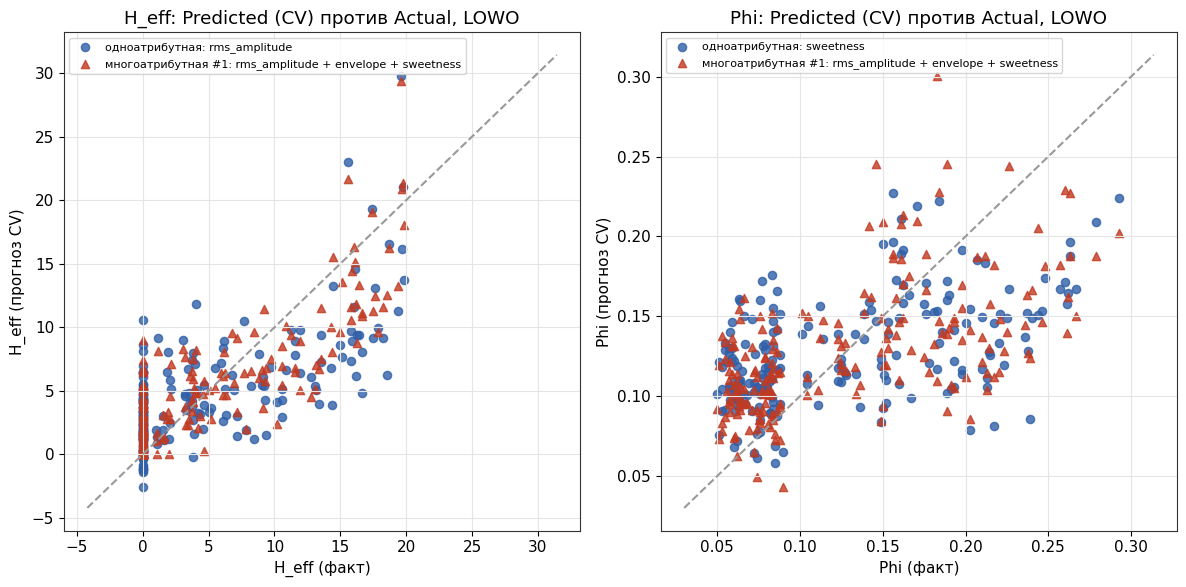

In [53]:
sc5 = out5["schemes"]["LOWO"]
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, param in zip(axes, ("H_eff", "Phi")):
    sb = sc5["single_best"].get(param)
    if sb:
        ax.scatter(sb["y_cv"], sb["oof"], s=35, color=BLUE, alpha=.8,
                   label=f"одноатрибутная: {sb['attr']}")
    det = sc5["details"].get((param, 1))
    if det:
        ax.scatter(det["actual"], det["pred"], s=35, color=RED, alpha=.8,
                   marker="^", label=f"многоатрибутная #1: {' + '.join(det['attrs'])}")
    lo_ = min(ax.get_xlim()[0], ax.get_ylim()[0]); hi_ = max(ax.get_xlim()[1], ax.get_ylim()[1])
    ax.plot([lo_, hi_], [lo_, hi_], "--", color="#999")
    ax.set_title(f"{param}: Predicted (CV) против Actual, LOWO")
    ax.set_xlabel(f"{param} (факт)"); ax.set_ylabel(f"{param} (прогноз CV)")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()


<div class="alert alert-info">
  <b> * <a href="#ch8">к содержанию</a> </b>
</div>

---

## Обобщение: другая пара параметров

Инструмент работает с любой парой числовых параметров. Ниже пара **Phi ↔ sweetness** (свойство ↔ атрибут), а затем **envelope ↔ rms_amplitude** (атрибут ↔ атрибут, проверка мультиколлинеарности). Для этого в движок подаются PARAM_1 и PARAM_2 под именами `Zprm_well` и `Zprm_map`.

In [41]:
# Свойство ↔ атрибут: Phi / sweetness (если колонки есть в файле)
if {"Phi", "sweetness"}.issubset(df.columns):
    d1 = df.dropna(subset=["Phi", "sweetness"]).copy()
    d1["Zprm_well"] = d1["Phi"]
    d1["Zprm_map"] = d1["sweetness"]
    s1 = sq.basic_crossplot_stats(d1)
    print(f"Phi / sweetness: n = {s1.n}, R²_lin = {s1.r2:.3f}, slope = {s1.slope:.3f}, "
          f"RMSE = {s1.rmse:.4f}, Bias = {s1.bias:+.4f} (ед. измерения колонок)")
else:
    print("Пара Phi / sweetness пропущена: нет нужных колонок")

# Атрибут ↔ атрибут: envelope / rms_amplitude (проверка мультиколлинеарности)
if {"envelope", "rms_amplitude"}.issubset(df.columns):
    d2 = df.dropna(subset=["envelope", "rms_amplitude"]).copy()
    d2["Zprm_well"] = d2["envelope"]
    d2["Zprm_map"] = d2["rms_amplitude"]
    s2 = sq.basic_crossplot_stats(d2)
    print(f"envelope / rms_amplitude: n = {s2.n}, R²_lin = {s2.r2:.3f}, slope = {s2.slope:.3f}, "
          f"p-value = {s2.p_value:.2e}")
    print("Высокий R² между атрибутами означает, что они дают почти одну и ту же информацию: "
          "в многоатрибутную модель лучше брать только один из них.")
else:
    print("Пара envelope / rms_amplitude пропущена: нет нужных колонок")


Phi / sweetness: n = 200, R²_lin = 0.270, slope = 0.844, RMSE = 0.0721, Bias = -0.0458 (ед. измерения колонок)
envelope / rms_amplitude: n = 200, R²_lin = 0.473, slope = 0.369, p-value = 2.27e-29
Высокий R² между атрибутами означает, что они дают почти одну и ту же информацию: в многоатрибутную модель лучше брать только один из них.


<div class="alert alert-info">
  <b> * <a href="#ch8">к содержанию</a> </b>
</div>

---

## __Выводы__ <a class="anchor" id="ch8_6"></a>

- Оценивайте связь по **out-of-sample** метрикам шага 2, а не по in-sample R² на всех скважинах. Разрыв между ними показывает степень оптимизма.
- **Random K-Fold систематически оптимистичнее** пространственных схем (LOWO, Block, Buffered, Spatial). Для пространственно коррелированных данных скважин его использовать как основной метод нельзя.
- Выбор атрибута делается **отдельно для H_eff и для Phi**. Шаг 5 показывает, даёт ли многоатрибутная модель выигрыш по RMSE_cv.
- Зоны и категории с систематически большим разбросом (шаги 2–3) — кандидаты для проверки интерпретации или качества сейсмики.
- Устойчивость к исключению скважин (шаги 4 и 4.5) показывает, зависит ли результат от отдельных скважин.
- Все выводы зависят от данных. Демонстрационный набор в этом ноутбуке синтетический. Для реальных выводов запустите ноутбук на своих данных.

Тот же движок лежит в основе интерактивного приложения `app_full.py` (Streamlit). Там доступны все шаги, выбор аппроксимаций, двуязычный интерфейс RU/EN и выделение точек кликом.

### Известные ограничения

- R²_lin и R²_fit — разные метрики. Их разведены по названию в таблицах, см. раздел «Метрики кросс-плота».
- Distance-based exclusion CV — упрощённая эвристика на расстояниях, а не полноценная вариограмма.
- Random K-Fold участвует в автоматическом выборе лучшей схемы по `score = RMSE + RMSE_fold_std`. Оптимистичная схема может быть выбрана лучшей. В текущей версии этот выбор не исключает её.
